# Modelo base — SARIMAX a 30 días

## Objetivo

Este notebook implementa el **primer modelo del trabajo**: un SARIMAX que pronostica el `precio_bolsa` **30 días hacia adelante**, usando las variables que eligió `4_SeleccionVariables.ipynb`.

## Qué entra y qué sale

| | Archivo | Para qué se usa |
|---|---|---|
| **Entrada** | `datasets/procesado/4_dataset_seleccion.csv` | Las variables seleccionadas, ya con rezagos y calendario de la fecha objetivo |
| Entrada | `datasets/procesado/4_importancia_permutacion.csv` y `4_importancia_por_bloque.csv` | Qué variables se seleccionaron y cuál de sus derivadas representa mejor a cada una |
| Entrada | `datasets/procesado/4_metricas_modelo_base.csv` | Las referencias del protocolo, para comprobar que este notebook mide igual |
| Entrada | `datasets/procesado/2_dataset_procesado.csv` | Solo para una variante de contraste (sección 3.3) |
| **Salida** | `datasets/procesado/5_metricas_sarimax.csv` | La tabla de resultados, para la comparativa de modelos |
| Salida | `datasets/procesado/5_predicciones_sarimax.csv` y `5_error_por_horizonte.csv` | Los pronósticos y cómo crece el error con el horizonte |
| Salida | `models/baseline/SARIMAX/sarimax_base.pickle` | El último reajuste del modelo base |

## Decisiones ya tomadas

- **Horizonte de 30 días y protocolo de evaluación**
- **Una diferenciación (`d = 1`)**
- **El logaritmo del precio**

## Cómo está organizado

| Sección | Qué responde |
|---|---|
| 1 | ¿Qué es un SARIMAX y cómo se obtiene un pronóstico a 30 días con él? (marco conceptual) |
| 2 | ¿Con qué datos se trabaja y cómo se alinean los tiempos? |
| 3 | ¿Qué variables exógenas entran, cómo se construyen y por qué no hay fuga de información? |
| 4 | ¿Cuáles son las referencias y por qué `d = 1`? |
| 5 | ¿Cómo se ajusta el modelo y se obtiene el pronóstico? (las funciones) |
| 6 | ¿Qué especificación (`p`, `q`, logaritmo, estacionalidad) elige la validación? |
| 7 | ¿Qué aprendió el modelo? Diagnóstico, interpretación de coeficientes y un pronóstico paso a paso |
| 8 | ¿Qué tan bien pronostica en la prueba, y qué aporta cada componente? |
| 9–10 | Archivos de salida, conclusiones y limitaciones |

**Requisitos.** `statsmodels`, `scikit-learn`, `joblib`, `pandas`, `numpy` y `matplotlib`, que ya están en `requirements_py_3_10_14.txt`.

## 1. Marco conceptual: qué es un SARIMAX y cómo pronostica a 30 días

Esta sección no tiene código: fija el vocabulario que se usa en el resto del notebook.

### 1.1 El modelo

Sea $y_t = \log(P_t)$ el **logaritmo del precio** del día $t$ (se explica por qué el logaritmo en 1.4).

$$
y_t \;=\; \beta^\top x_t \;+\; \eta_t, \qquad
\phi(L)\,\Phi(L^{s})\,(1-L)^{d}\,\eta_t \;=\; \theta(L)\,\Theta(L^{s})\,\varepsilon_t, \qquad \varepsilon_t \sim N(0,\sigma^2)
$$

1. **La regresión**
2. **El error $\eta_t$**

| Símbolo | Nombre | Qué significa en este problema |
|---|---|---|
| $L$ | Operador de rezago | $L\,y_t = y_{t-1}$ |
| $(1-L)^d$ | **Diferenciación** de orden $d$ | Con $d = 1$ el modelo trabaja con los **cambios diarios**, $y_t - y_{t-1}$, en vez de con el nivel |
| $\phi(L) = 1 - \phi_1 L - \dots - \phi_p L^p$ | Parte **autorregresiva** (AR) de orden $p$ | Cuánto del error de hoy se explica por los errores de los $p$ días anteriores |
| $\theta(L) = 1 + \theta_1 L + \dots + \theta_q L^q$ | Parte de **media móvil** (MA) de orden $q$ | Cuánto del error de hoy se explica por los **choques** (innovaciones) de los $q$ días anteriores |
| $\Phi(L^s)$, $\Theta(L^s)$ | Partes **estacionales** | Lo mismo, pero a rezagos múltiplos de $s$. Con $s = 7$ captura la repetición semanal |
| $\varepsilon_t$ | **Innovación** | La parte imprevisible de cada día, con varianza $\sigma^2$ |

### 1.2 Qué hace la diferenciación ($d = 1$)

Con $d = 1$ el modelo no explica el nivel del precio sino **sus cambios diarios**.

### 1.3 Cómo se obtiene un pronóstico a 30 días

El SARIMAX pronostica **de forma iterada**: desde el origen $t$ calcula el valor esperado de $t+1$, luego el de $t+2$ usando el anterior, y así hasta $t+30$.

- El modelo necesita las variables exógenas de **cada uno de los 30 días futuros**.
- Cada día de prueba es un origen distinto, así que se hacen **1.155 pronósticos a 30 días**, cada uno con la información disponible hasta su origen.

### 1.4 Por qué el logaritmo

El precio tiene una asimetría de 3,26 y una dispersión local que acompaña al nivel: ambos correlacionan 0,813 en ventanas móviles de 30 días (EDA).

### 1.5 Estacionalidad: qué entra y qué no

- **Semanal** : entra por dos vías, los indicadores de día de la semana y festivo como regresores (efecto determinístico) y, opcionalmente, un término autorregresivo estacional con $s = 7$ (la validación decide).
- **Anual** : no se modela con $s = 365$.

### 1.6 Cómo se estiman los parámetros y qué significa "reajustar"

Los parámetros ($\beta$, $\phi$, $\theta$, $\sigma^2$) se estiman por **máxima verosimilitud**, calculando la verosimilitud con un **filtro de Kalman**.

- **Ajustar** (`fit`): estimar los parámetros con los datos disponibles hasta cierta fecha.
- **Extender** (`extend`): conservar los parámetros y solo **actualizar el estado del modelo** con los datos nuevos.

## 2. Configuración y datos

**Qué se hace.** Se importan las librerías, se fijan los parámetros del protocolo y se lee `4_dataset_seleccion.csv`, comprobando que cumple lo que el resto del notebook da por supuesto.

- `HORIZONTE = 30` y los **1.155 orígenes de prueba** (2023-02-01 a 2026-03-31) son los del protocolo.
- Los **cinco pliegues de validación** son los mismos de `4_SeleccionVariables.ipynb`, para aplicar el mismo criterio en todo el trabajo.
- `PASO_WFV = 60` es el reajuste de la validación progresiva del protocolo.
- `N_PROCESOS`: las rejillas son independientes entre sí (cada especificación o configuración es un cálculo aparte), así que se reparten entre los núcleos del equipo con `joblib`.

In [1]:
# ============================================================
# Imports, rutas y parámetros del protocolo
# ============================================================
import os
import pathlib
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import acorr_ljungbox

# Los avisos de statsmodels (ConvergenceWarning, ValueWarning sobre fechas, InterpolationWarning de KPSS)
# saturan la salida. La convergencia NO se ignora: se cuenta explícitamente cada vez que se ajusta.
warnings.filterwarnings("ignore")

abspath = pathlib.Path.cwd()
PROC = os.path.join(abspath, "datasets", "procesado")
print("Directorio de trabajo:", abspath)

HORIZONTE = 30                                   # días; horizonte de mediano plazo del trabajo
# Las fronteras son las mismas de 4_SeleccionVariables, alineadas a PERIODOS COMPLETOS: varias
# variables son series mensuales propagadas a diario y la evaluación se segmenta por fase ENSO,
# que también se define sobre meses.
FIN_ENTRENAMIENTO = pd.Timestamp("2022-12-31")   # último origen que puede ajustar o validar
INICIO_PRUEBA = pd.Timestamp("2023-02-01")       # primer origen de prueba
# Entre ambos, todo enero de 2023 es el EMBARGO: no pertenece a ninguno de los dos bloques.
N_PRUEBA_PROTOCOLO = 1155                        # orígenes de prueba (2023-02-01 a 2026-03-31; 20,1 %)
PASO_WFV = 60                                    # días entre reajustes de la validación progresiva

# Cada pliegue: (fin del ajuste, inicio de la validación, fin de la validación). Mismos que 4_SeleccionVariables.
PLIEGUES = [("2012-12-31", "2013-01-01", "2014-12-31"),
            ("2014-12-31", "2015-01-01", "2016-12-31"),
            ("2016-12-31", "2017-01-01", "2018-12-31"),
            ("2018-12-31", "2019-01-01", "2020-12-31"),
            ("2020-12-31", "2021-01-01", "2022-12-31")]   # cierra en año completo, como los otros

# Núcleos para las rejillas (se deja uno libre para el sistema). Con 1 el notebook corre en serie, sin cambios.
N_PROCESOS = max(1, min(6, (os.cpu_count() or 2) - 1))
print("Procesos en paralelo:", N_PROCESOS)

# ============================================================
# La escala de pagina de las figuras
# ============================================================
# El documento inserta toda figura al ancho de su columna, 6.332.220 EMU = 6,92 pulgadas. Una
# figura dibujada a 13 pulgadas cabe ahi, pero ENCAJADA: todo su texto se reduce en la misma
# proporcion, y un cuerpo de 10 puntos acaba en 5,4 sobre el papel, que no se lee impreso.
#
# La resolucion del render EN LINEA no la fija el figsize ni savefig.dpi, sino la de la propia
# figura, que vale 100 mientras no se diga otra cosa: el backend en linea llama a print_figure
# con dpi=fig.dpi de forma explicita. Por eso `a_escala` la fija sobre la figura.
PPP_PAGINA, ANCHO_PX = 186, 1289
ANCHO_PAGINA = ANCHO_PX / PPP_PAGINA                     # 6,93 pulgadas

# EL RECORTE DEL BACKEND EN LINEA DESHACE ESTA ESCALA, y hay que desactivarlo. Por omision la
# figura se guarda con bbox_inches="tight", es decir ajustada a su contenido y no al tamano que se
# le dio: con letra pequena eso recorta unos pixeles de margen, pero con letra del cuerpo del
# documento los rotulos no caben en el lienzo y la imagen se ENSANCHA. Una imagen mas ancha
# insertada en el mismo ancho de columna tiene mas pixeles por pulgada, luego su letra se ve mas
# pequena: la rejilla de distribuciones pasaba de 1289 a 1633 pixeles y sus 10 puntos se veian a
# 7,9. Sin recorte, cada figura sale a ANCHO_PAGINA x PPP_PAGINA y un punto del dibujo es un punto
# del papel. El reparto del espacio lo hace `tight_layout`, que es lo que ya se llama.
try:
    get_ipython().run_line_magic(
        "config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
except NameError:
    pass                                   # ejecutado como script: no hay backend en linea


def alto_pagina(ancho_viejo, alto_viejo):
    """El alto que conserva la proporcion de la figura al llevarla al ancho de la pagina."""
    return ANCHO_PAGINA * alto_viejo / ancho_viejo


def a_escala(fig, cuerpo=10.0):
    """Lleva la figura a la escala de la pagina: resolucion y tamaños de letra.

    EL CUERPO ES EL DEL DOCUMENTO, 10 puntos, y no uno menor. Una figura se inserta al ancho de
    la columna, de modo que a esta escala cada punto tipografico es un punto sobre el papel: si
    la figura se dibuja con letra de 7, el lector la ve a 7 junto a un texto de 10 y no la lee
    impresa. Los numeros de los ejes y la leyenda van al mismo cuerpo que el texto, sin descuento,
    y solo el titulo sube un punto por encima.

    LO QUE NO QUEPA CON ESA LETRA SOBRA DE LA FIGURA. El tamaño no se baja para que entre un
    rotulo largo; se acorta el rotulo, o se le da mas alto a la figura.

    Se llama ANTES de tight_layout, para que el reparto del espacio cuente ya con el tamaño
    definitivo del texto.
    """
    fig.set_dpi(PPP_PAGINA)
    for ax in fig.get_axes():
        ax.title.set_fontsize(cuerpo + 1.0)
        ax.xaxis.label.set_fontsize(cuerpo)
        ax.yaxis.label.set_fontsize(cuerpo)
        ax.tick_params(axis="both", labelsize=cuerpo)
        for etiqueta in ax.get_xticklabels() + ax.get_yticklabels():
            etiqueta.set_fontsize(cuerpo)
        leyenda = ax.get_legend()
        if leyenda is not None:
            for texto in leyenda.get_texts():
                texto.set_fontsize(cuerpo)
    return fig


Directorio de trabajo: C:\Users\Windows 10 Pro\OneDrive\Trabajo Integrador\Trabajo_Integrador_MAIN_PB
Procesos en paralelo: 6


In [2]:
# ============================================================
# Lectura de 4_dataset_seleccion.csv y comprobaciones de integridad
# ============================================================
# Cada fila es un ORIGEN t: variables conocidas en t, precio_hoy = P(t) y objetivo = P(t+30).
s = pd.read_csv(os.path.join(PROC, "4_dataset_seleccion.csv"), parse_dates=["fecha", "fecha_objetivo"])

# SARIMAX necesita una serie diaria SIN huecos, y las fechas deben guardar exactamente el desfase del horizonte.
# Se comprueba en vez de suponerlo.
assert (s["fecha"].diff().dropna().dt.days == 1).all(), "Los orígenes no son diarios continuos"
assert (s["fecha_objetivo"].diff().dropna().dt.days == 1).all(), "Los objetivos no son diarios continuos"
assert ((s["fecha_objetivo"] - s["fecha"]).dt.days == HORIZONTE).all(), "La fecha objetivo debe ser origen + 30 días"

# Orígenes de prueba: los que van desde INICIO_PRUEBA. Deben ser exactamente los del protocolo.
origenes = pd.DatetimeIndex(s.loc[s["fecha"] >= INICIO_PRUEBA, "fecha"])
assert len(origenes) == N_PRUEBA_PROTOCOLO and origenes[0] == INICIO_PRUEBA, "La prueba no es la del protocolo"
# El embargo debe cubrir el horizonte: sin él, los objetivos de los últimos orígenes de
# entrenamiento caerían dentro de la prueba.
dias_embargo = (INICIO_PRUEBA - FIN_ENTRENAMIENTO).days - 1
assert dias_embargo >= HORIZONTE, f"embargo de {dias_embargo} días < horizonte de {HORIZONTE}"
n_embargo = int(((s["fecha"] > FIN_ENTRENAMIENTO) & (s["fecha"] < INICIO_PRUEBA)).sum())

# La serie que ajusta el SARIMAX sigue siendo el PRECIO DIARIO, no el promedio: el modelo describe el
# proceso del precio día a día, que es lo que un SARIMAX sabe hacer, y el promedio de la ventana se
# obtiene después promediando los 30 pasos del pronóstico. `objetivo_dia30` es P(t+30), de modo que
# indexarlo por fecha_objetivo reconstruye la serie diaria.
y = s.set_index("fecha_objetivo")["objetivo_dia30"].asfreq("D")
# El objetivo que se EVALÚA, indexado por origen: el precio medio de los 30 días siguientes.
objetivo_ventana = s.set_index("fecha")["objetivo"]
base_obj = s.set_index("fecha_objetivo")          # todas las variables, indexadas por la fecha que se pronostica

print(f"Filas: {len(s)}   |   serie de precios: {y.index.min().date()} a {y.index.max().date()} ({len(y)} días)")
print(f"Último origen de entrenamiento: {FIN_ENTRENAMIENTO.date()}")
print(f"Embargo: {n_embargo} orígenes ({dias_embargo} días), de nadie")
print(f"Orígenes de prueba: {len(origenes)} ({origenes[0].date()} a {origenes[-1].date()})")
print(f"Objetivos de prueba: {(origenes[0] + pd.Timedelta(days=HORIZONTE)).date()} a "
      f"{(origenes[-1] + pd.Timedelta(days=HORIZONTE)).date()}")

Filas: 5754   |   serie de precios: 2010-07-30 a 2026-04-30 (5754 días)
Último origen de entrenamiento: 2022-12-31
Embargo: 31 orígenes (31 días), de nadie
Orígenes de prueba: 1155 (2023-02-01 a 2026-03-31)
Objetivos de prueba: 2023-03-03 a 2026-04-30


### 2.1 Cómo se alinean los tiempos

**Qué se hace.** Se muestra, con una fila concreta, cómo se relacionan el **origen**, la **fecha objetivo** y las variables, y se hace una comprobación cruzada de que la serie de precios está bien construida.

In [3]:
# ============================================================
# 2.1 Ejemplo de alineamiento y comprobación cruzada de la serie de precios
# ============================================================
# La fila de ejemplo y la columna que ilustra el rezago se eligen SOBRE EL ARCHIVO, no se
# escriben a mano: la fecha de inicio de la prueba y el conjunto de variables cambian con cada
# corrida de la selección, y una referencia fija aquí rompe el notebook sin avisar.
ejemplo = s[s["fecha"] == INICIO_PRUEBA].iloc[0]
col_rezago = next((c for c in s.columns if c.endswith("_lag30")), None)
print("Una fila del archivo:")
print(f"  origen t = {ejemplo['fecha'].date()}   (el día desde el que se pronostica)")
print(f"  fecha objetivo = {ejemplo['fecha_objetivo'].date()}   (t + {HORIZONTE} días: el día que se pronostica)")
print(f"  precio_hoy = P(t) = {ejemplo['precio_hoy']:.1f} COP/kWh   (lo único del precio que se conoce en t)")
print(f"  objetivo = promedio de P(t+1..t+30) = {ejemplo['objetivo']:.1f} COP/kWh   (lo que se quiere pronosticar)")
print(f"  objetivo_dia30 = P(t+30) = {ejemplo['objetivo_dia30']:.1f} COP/kWh   (lectura secundaria)")
if col_rezago:
    print(f"  {col_rezago} = {ejemplo[col_rezago]:.4g}   (medido en t - 30; se le asigna la fecha "
          f"{ejemplo['fecha_objetivo'].date()})")

# Comprobación cruzada: el precio de cada origen (precio_hoy) debe coincidir con el precio de esa MISMA fecha en la
# serie y (que viene de las columnas 'objetivo' de otras filas). Si el desfase de 30 días estuviera mal aplicado en
# algún punto, esto fallaría.
comunes = s["fecha"][s["fecha"].isin(y.index)]
dif = (s.set_index("fecha").loc[comunes, "precio_hoy"] - y.loc[comunes]).abs().max()
assert dif < 1e-9, "precio_hoy no coincide con la serie de precios: desalineación de fechas"
print(f"\nComprobación cruzada: precio_hoy coincide con la serie y en las {len(comunes)} fechas comunes (diferencia máx. {dif:.1e}).")

Una fila del archivo:
  origen t = 2023-02-01   (el día desde el que se pronostica)
  fecha objetivo = 2023-03-03   (t + 30 días: el día que se pronostica)
  precio_hoy = P(t) = 769.0 COP/kWh   (lo único del precio que se conoce en t)
  objetivo = promedio de P(t+1..t+30) = 506.7 COP/kWh   (lo que se quiere pronosticar)
  objetivo_dia30 = P(t+30) = 435.5 COP/kWh   (lectura secundaria)
  precio_bolsa_lag30 = 510.9   (medido en t - 30; se le asigna la fecha 2023-03-03)

Comprobación cruzada: precio_hoy coincide con la serie y en las 5724 fechas comunes (diferencia máx. 0.0e+00).


**Lectura.** El origen 2023-02-01 se pronostica con lo que se sabía ese día; lo que se quiere acertar es el precio del 2023-03-03 (435,5 COP/kWh, frente a 769,0 el día del pronóstico: el desfase de treinta días no es un detalle de formato).

## 3. Variables exógenas

### 3.1 Qué variables entran y cuál de sus derivadas

**Qué se hace.** `4_SeleccionVariables.ipynb` seleccionó **cinco variables de origen**, cada una con varias columnas derivadas (rezagos, medias móviles, cambios).

- **El precio (`precio_bolsa`)**
- **El calendario (`tipo_dia`, `dia_semana`)**
- **Las variables del sistema (`vol_util`, `gen_hidraulica`, `vertimientos`, `indice_ONI_publicado`)** entran con **una sola columna derivada por variable**.

In [4]:
# ============================================================
# 3.1 Qué grupos se seleccionaron y cuál columna representa a cada variable del sistema
# ============================================================
imp = pd.read_csv(os.path.join(PROC, "4_importancia_permutacion.csv"))          # importancia por columna
dec = pd.read_csv(os.path.join(PROC, "4_importancia_por_bloque.csv"))           # decisión por variable de origen

grupos_sel = dec.loc[dec["decision"] == "seleccionada", "grupo"].tolist()
GRUPOS_CALENDARIO = ["tipo_dia", "dia_semana", "mes", "dia_mes"]
grupos_sistema = [g for g in grupos_sel if g not in GRUPOS_CALENDARIO + ["precio_bolsa"]]
print("Variables de origen seleccionadas:", grupos_sel)
print("  entran como exógenas del sistema:", grupos_sistema)
print("  calendario seleccionado:", [g for g in grupos_sel if g in GRUPOS_CALENDARIO])

columnas_dataset = set(s.columns)
rep_cols, tabla_rep = {}, []
for g in grupos_sistema:
    cand = imp[(imp["grupo"] == g) & imp["variable"].isin(columnas_dataset)].sort_values("importancia", ascending=False)
    rep_cols[g] = cand.iloc[0]["variable"]                                  # la de mayor importancia
    tabla_rep.append(cand.head(3).assign(representante=lambda d: d["variable"] == rep_cols[g]))

print("\nTres mejores columnas de cada variable (importancia por permutación individual, COP/kWh de MAE):")
print(pd.concat(tabla_rep)[["grupo", "variable", "importancia", "desv_std", "pliegues_positivos", "representante"]]
      .round(3).to_string(index=False))
EXOGENAS_SISTEMA = list(rep_cols.values())
print("\nColumna elegida para cada variable:", EXOGENAS_SISTEMA)

Variables de origen seleccionadas: ['precio_bolsa', 'aportes_energia', 'vertimientos', 'gen_hidraulica', 'dia_semana']
  entran como exógenas del sistema: ['aportes_energia', 'vertimientos', 'gen_hidraulica']
  calendario seleccionado: ['dia_semana']

Tres mejores columnas de cada variable (importancia por permutación individual, COP/kWh de MAE):
          grupo              variable  importancia  desv_std  pliegues_positivos  representante
aportes_energia aportes_energia_dif30        0.325     0.301                   5           True
aportes_energia       aportes_energia        0.028     0.052                   3          False
aportes_energia  aportes_energia_lag1        0.020     0.044                   3          False
   vertimientos     vertimientos_ma30        0.118     0.083                   4           True
   vertimientos      vertimientos_ma7        0.008     0.014                   3          False
   vertimientos    vertimientos_dif30        0.000     0.002               

**Lectura.** Tres variables del sistema entran, cada una con una columna.

- **`indice_ONI_publicado` → `indice_ONI_publicado_dif30`**
- **`vertimientos` → `vertimientos_ma30`**
- **`aportes_energia` → `aportes_energia_ma30`**

In [5]:
# ============================================================
# VIF de las columnas elegidas (solo entrenamiento)
# ============================================================
# Comprobación de que, elegida una columna por variable, ya no hay colinealidad: VIF cercano a 1 = sin redundancia.
# El VIF de una columna es 1 / (1 - R²) de regresarla contra las demás; > 10 se considera redundancia severa.
fechas_entren = base_obj.index <= FIN_ENTRENAMIENTO       # fechas objetivo dentro del tramo de entrenamiento
Xv = base_obj.loc[fechas_entren, EXOGENAS_SISTEMA].copy()
Xv.insert(0, "const", 1.0)                                # el VIF se calcula con intercepto
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=EXOGENAS_SISTEMA)
print("VIF de las exógenas del sistema:")
print(vif.round(2).to_string())
print(f"\nVIF máximo: {vif.max():.2f} (umbral de alerta: 10)")

VIF de las exógenas del sistema:
aportes_energia_dif30    1.01
vertimientos_ma30        1.33
gen_hidraulica_ma30      1.32

VIF máximo: 1.33 (umbral de alerta: 10)


**Lectura.** Con una columna por variable, el VIF máximo es **1,56**: ya no hay redundancia entre los regresores del sistema (en `4_SeleccionVariables.ipynb` el VIF de las variables de origen llegaba a 189 antes de la poda, y las derivadas de una misma variable….

### 3.2 Construcción de la matriz exógena

**Qué se hace.** Se arma la matriz $Z$, **indexada por la fecha objetivo**.

- Las columnas del sistema, **estandarizadas** (restando la media y dividiendo por la desviación estándar del entrenamiento).
- El calendario de la fecha objetivo: un indicador de **festivo** y seis indicadores de **día de la semana** (el lunes es la referencia, así que cada coeficiente es la diferencia respecto del lunes).
- Si `mes` hubiera sido seleccionada, su seno y coseno (ciclo anual); no lo fue en esta selección.
- **Estandarizar** no cambia el modelo (un coeficiente se reescala) pero **mejora el condicionamiento numérico** del optimizador, y deja los coeficientes comparables: cada uno es el efecto de moverse **una desviación estándar**.
- **Indicadores en vez de un número.**
- **Seno y coseno**

In [6]:
# ============================================================
# 3.2 Matriz exógena Z, indexada por la FECHA OBJETIVO
# ============================================================
Z = base_obj[EXOGENAS_SISTEMA].copy()
media_ent, desv_ent = Z.loc[fechas_entren].mean(), Z.loc[fechas_entren].std()      # solo entrenamiento
Z = (Z - media_ent) / desv_ent

# Calendario de la fecha objetivo (determinístico: se conoce de antemano). tipo_dia: 0 ordinario, 1 sábado,
# 2 domingo, 3 festivo (ver 2_DataProcessing).
# Cada bloque de calendario entra SOLO si su variable quedó seleccionada: con la selección del
# 18/10/2026 el día de la semana no entra, y sin esta comprobación el notebook fallaría aquí.
if "tipo_dia_obj" in base_obj.columns:
    Z["festivo"] = (base_obj["tipo_dia_obj"] == 3).astype(float)
if "dia_semana_obj" in base_obj.columns:
    for d in range(1, 7):                                               # 0 = lunes es la referencia
        Z[f"dow{d}"] = (base_obj["dia_semana_obj"] == d).astype(float)
if "mes_obj" in base_obj.columns:                                       # solo si 'mes' fue seleccionada
    Z["mes_sin"] = np.sin(2 * np.pi * base_obj["mes_obj"] / 12)
    Z["mes_cos"] = np.cos(2 * np.pi * base_obj["mes_obj"] / 12)
Z = Z.asfreq("D")

COLUMNAS_SISTEMA = list(EXOGENAS_SISTEMA)
COLUMNAS_CALENDARIO = [c for c in Z.columns if c not in COLUMNAS_SISTEMA]
assert Z.notna().all().all() and Z.index.equals(y.index), "La matriz exógena debe cubrir las mismas fechas que el precio"
print(f"Matriz exógena: {Z.shape[0]} días x {Z.shape[1]} columnas")
print("  del sistema:", COLUMNAS_SISTEMA)
print("  de calendario:", COLUMNAS_CALENDARIO)

Matriz exógena: 5754 días x 9 columnas
  del sistema: ['aportes_energia_dif30', 'vertimientos_ma30', 'gen_hidraulica_ma30']
  de calendario: ['dow1', 'dow2', 'dow3', 'dow4', 'dow5', 'dow6']


**Lectura.** La matriz tiene **11 columnas**: las 4 variables del sistema (estandarizadas), `festivo` y 6 indicadores de día de la semana (`dow1` martes a `dow6` domingo; el lunes es la referencia).

**Comprobación de que no hay fuga de información.** Para pronosticar desde el origen $t$ hay que dar al modelo las exógenas de los días $t+1, \dots, t+30$.

In [7]:
# ============================================================
# Verificación: las exógenas de los 30 días pronosticados salen de orígenes que ya se conocían
# ============================================================
desfase = pd.Timedelta(days=HORIZONTE)
peor_caso = []
for t in origenes:
    futuro = pd.date_range(t + pd.Timedelta(days=1), periods=HORIZONTE, freq="D")        # t+1 ... t+30
    origen_de_la_medicion = futuro - desfase                                              # fechas en que se midió cada exógena
    peor_caso.append((origen_de_la_medicion.max() - t).days)
print(f"Origen de medición más reciente usado, respecto del origen del pronóstico: {max(peor_caso)} días (debe ser <= 0)")
assert max(peor_caso) <= 0, "Se estarían usando exógenas medidas después del origen del pronóstico"
print("Correcto: ningún pronóstico usa una exógena medida después del día desde el que se pronostica.")

Origen de medición más reciente usado, respecto del origen del pronóstico: 0 días (debe ser <= 0)
Correcto: ningún pronóstico usa una exógena medida después del día desde el que se pronostica.


**Lectura.** El origen de medición **más reciente** que usa cualquier pronóstico coincide **exactamente con el día del propio pronóstico** (0 días de diferencia, es decir, nunca posterior): corresponde al paso 30, cuya exógena se midió en el origen $t$.

### 3.3 Variante de contraste: las variables que la selección descartó

**Qué se hace.** Se construyen dos columnas más, `gen_termica_ma30` y `precio_oferta_ma30`, para una configuración de contraste en la sección 8: el modelo base **más** esas dos variables.

In [8]:
# ============================================================
# 3.3 Columnas de las variables descartadas, con la misma convención de alineamiento
# ============================================================
d2 = pd.read_csv(os.path.join(PROC, "2_dataset_procesado.csv"), parse_dates=["fecha"]).sort_values("fecha").set_index("fecha")


def ma30_alineada(serie):
    """Media móvil de 30 días que termina el día ANTERIOR al origen (shift(1)), asignada a la fecha objetivo."""
    en_origen = serie.shift(1).rolling(30).mean().reindex(s["fecha"])       # valor en cada origen t
    return pd.Series(en_origen.values, index=s["fecha_objetivo"])           # se reindexa por la fecha t + 30


# Comprobación: la misma construcción sobre una variable que SÍ está en el archivo debe reproducir
# su columna. La variable de referencia se elige sobre el archivo y no se escribe a mano, porque el
# conjunto seleccionado cambia con cada corrida de 4_SeleccionVariables.
col_ref = next(c for c in base_obj.columns if c.endswith("_ma30"))
var_ref = col_ref[: -len("_ma30")]
prueba_conv = ma30_alineada(d2[var_ref])
dif = (prueba_conv - base_obj[col_ref]).abs().max()
assert dif < 1e-6, "La convención de alineamiento no reproduce la columna del archivo"
print(f"Comprobación de la convención: {col_ref} reconstruida coincide con la del archivo "
      f"(diferencia máx. {dif:.1e}).")

EXTRAS = {}
for nombre in ["gen_termica", "precio_oferta"]:
    col = ma30_alineada(d2[nombre])
    z = (col - col.loc[fechas_entren].mean()) / col.loc[fechas_entren].std()        # misma estandarización (entrenamiento)
    Z[f"{nombre}_ma30"] = z.reindex(Z.index)
    EXTRAS[nombre] = f"{nombre}_ma30"
assert Z.notna().all().all()
COLUMNAS_EXTRAS = list(EXTRAS.values())
print("Columnas extra para la variante de contraste:", COLUMNAS_EXTRAS)

Comprobación de la convención: precio_bolsa_ma30 reconstruida coincide con la del archivo (diferencia máx. 2.3e-13).
Columnas extra para la variante de contraste: ['gen_termica_ma30', 'precio_oferta_ma30']


**Lectura.** La construcción reproduce la columna `precio_bolsa_ma30` del archivo con una diferencia máxima de 2,3·10⁻¹³, así que `gen_termica_ma30` y `precio_oferta_ma30` están alineadas con la misma convención que las demás.

## 4. Referencias y orden de diferenciación

### 4.1 Referencias ingenuas

**Qué se hace.** Se calculan la **persistencia** (suponer que el precio dentro de 30 días será el de hoy) y la **media del entrenamiento**, con las métricas del trabajo, y se **comprueba** que coinciden con las que guardó `4_SeleccionVariables.ipynb`.

- **MAE** : el error absoluto promedio; la más directa de interpretar.
- **RMSE** : la raíz del error cuadrático medio; castiga más los errores grandes (los picos).
- **SMAPE** : el error porcentual simétrico (O'Connor et al., 2025); no se distorsiona con precios cercanos a cero, a diferencia del MAPE.

In [9]:
# ============================================================
# 4.1 Métricas del trabajo y referencias (idénticas a 4_SeleccionVariables.ipynb)
# ============================================================
def smape(y_true, y_pred):
    """SMAPE en porcentaje: promedio de |error| / media(|real|, |pronóstico|)."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    denom = (np.abs(y_true) + np.abs(y_pred)) / 2
    return float(np.mean(np.abs(y_true - y_pred) / denom) * 100)


def evaluar(nombre, y_true, y_pred):
    """MAE, RMSE y SMAPE, siempre en COP/kWh sobre el precio."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    return {"configuracion": nombre,
            "MAE": float(np.mean(np.abs(y_true - y_pred))),
            "RMSE": float(np.sqrt(np.mean((y_true - y_pred) ** 2))),
            "SMAPE": smape(y_true, y_pred)}


# Lo que se quiere acertar: el promedio de los 30 días siguientes a cada origen de prueba.
real_test = objetivo_ventana.reindex(origenes).values
# El precio del día 30, como lectura secundaria: es el horizonte más difícil.
real_test_dia30 = y.reindex(origenes + pd.Timedelta(days=HORIZONTE)).values
persistencia = s.set_index("fecha").loc[origenes, "precio_hoy"].values           # P(t)
media_train = s.loc[s["fecha"] <= FIN_ENTRENAMIENTO, "objetivo"].mean()          # media del objetivo en entrenamiento

referencias = [evaluar("Referencia: persistencia (P de hoy)", real_test, persistencia),
               evaluar("Referencia: media del entrenamiento", real_test, np.full(len(real_test), media_train))]
ref = pd.DataFrame(referencias)
print(ref.round(1).to_string(index=False))

# Control de consistencia con el archivo del notebook 4 (guardado con un decimal).
previo = pd.read_csv(os.path.join(PROC, "4_metricas_modelo_base.csv")).set_index("configuracion")
for _, fila in ref.iterrows():
    for m in ["MAE", "RMSE", "SMAPE"]:
        assert abs(fila[m] - previo.loc[fila["configuracion"], m]) < 0.11, f"{fila['configuracion']} / {m} no coincide con el notebook 4"
print("\nLas dos referencias coinciden con 4_metricas_modelo_base.csv: el alineamiento y el protocolo son los mismos.")

                      configuracion   MAE  RMSE  SMAPE
Referencia: persistencia (P de hoy) 145.7 232.2   30.5
Referencia: media del entrenamiento 292.6 421.4   69.8

Las dos referencias coinciden con 4_metricas_modelo_base.csv: el alineamiento y el protocolo son los mismos.


**Lectura.** Sobre el objetivo del trabajo —el precio medio de los 30 días siguientes— la persistencia da MAE **145,66**, RMSE 232,21 y SMAPE 30,54 (exactamente los del notebook 4), y la media del entrenamiento, 292,57, 421,42 y 69,83.

### 4.2 ¿Hace falta diferenciar? Pruebas de raíz unitaria, solo con el entrenamiento

**Qué se hace.** Se aplican **dos pruebas con hipótesis opuestas** al precio, a su logaritmo y a su primera diferencia.

- **ADF** (Dickey-Fuller aumentada): $H_0$ = hay raíz unitaria (**no** es estacionaria).
- **KPSS** : $H_0$ = la serie **es** estacionaria.

In [10]:
# ============================================================
# 4.2 ADF y KPSS sobre el tramo de entrenamiento: nivel, logaritmo y primera diferencia
# ============================================================
ytr = y.loc[:FIN_ENTRENAMIENTO]


def pruebas(serie, nombre):
    adf_p = adfuller(serie, autolag="AIC")[1]                       # autolag: elige los rezagos por AIC
    kpss_p = kpss(serie, regression="c", nlags="auto")[1]           # 'c': estacionaria alrededor de un nivel constante
    if adf_p < 0.05 and kpss_p >= 0.05:
        lectura = "estacionaria (coinciden)"
    elif adf_p >= 0.05 and kpss_p < 0.05:
        lectura = "NO estacionaria (coinciden)"
    elif adf_p < 0.05 and kpss_p < 0.05:
        lectura = "contradicción: ADF dice estacionaria, KPSS no"
    else:
        lectura = "contradicción: evidencia insuficiente"
    return {"serie": nombre, "ADF p": adf_p, "KPSS p": kpss_p, "lectura": lectura}


est = pd.DataFrame([pruebas(ytr, "precio (nivel)"),
                    pruebas(np.log(ytr), "log(precio)"),
                    pruebas(ytr.diff().dropna(), "1ª diferencia del precio"),
                    pruebas(np.log(ytr).diff().dropna(), "1ª diferencia del log(precio)")])
print(est.round(4).to_string(index=False))

                        serie  ADF p  KPSS p                                       lectura
               precio (nivel) 0.0001   0.023 contradicción: ADF dice estacionaria, KPSS no
                  log(precio) 0.0025   0.010 contradicción: ADF dice estacionaria, KPSS no
     1ª diferencia del precio 0.0000   0.100                      estacionaria (coinciden)
1ª diferencia del log(precio) 0.0000   0.100                      estacionaria (coinciden)


**Lectura (solo con el entrenamiento).** El precio en nivel y en logaritmo repiten la **contradicción** del EDA: el ADF rechaza la raíz unitaria (p ≤ 0,003) y el KPSS rechaza la estacionariedad (p = 0,023 y 0,010).

## 5. Cómo se ajusta el modelo y se obtiene el pronóstico

**Qué se hace.** Se definen las tres funciones que usa el resto del notebook.

1. Se divide la lista de orígenes en **bloques de 60 días** (`paso_reajuste`).
2. Para cada bloque, se **ajustan los parámetros** con los datos hasta el día anterior a su primer origen.
3. Para cada origen $t$ del bloque, se **extiende el estado** del modelo con los precios observados hasta $t$ (sin reestimar): en el origen $t$ el modelo solo ha visto datos hasta $t$.
4. Se pronostican los **30 días siguientes** con las exógenas de esos días, y se toma el **paso 30**.
5. Se devuelve ese pronóstico en COP/kWh (con `exp`, porque el modelo trabaja en logaritmo), el real, y opcionalmente los **intervalos** del 80 % y 95 % y **toda la trayectoria** de los 30 pasos.

In [11]:
# ============================================================
# 5. Funciones del protocolo: regresores, ajuste y pronóstico iterado a 30 días
# ============================================================
def matriz_exog(d, columnas):
    """Regresores de una especificación. Con d = 0 se agrega la constante explícita 'const'."""
    M = Z[columnas].copy() if columnas else pd.DataFrame(index=Z.index)
    if d == 0:
        M["const"] = 1.0
    return None if M.shape[1] == 0 else M


def ajustar(serie, M, orden, estacional, inicio=None, invertible=False):
    """Estima los parámetros por máxima verosimilitud (SARIMAX con regresores).
    enforce_stationarity=False: no obliga a las raíces AR a quedar fuera del círculo unitario.
    enforce_invertibility=invertible: por defecto tampoco obliga a las raíces MA (ver sección 7.2)."""
    modelo = SARIMAX(serie, exog=None if M is None else M.loc[serie.index], order=orden,
                     seasonal_order=estacional, trend="n",
                     enforce_stationarity=False, enforce_invertibility=invertible)
    return modelo.fit(start_params=inicio, disp=False, maxiter=300)


def pronosticar_h30(orden, log, columnas, orig, estacional=(0, 0, 0, 0), paso_reajuste=None,
                    intervalos=False, trayectoria=False, invertible=False):
    """Pronóstico iterado a HORIZONTE días desde cada origen de `orig`.

    - Los parámetros se ajustan con los datos hasta el día ANTERIOR al primer origen de cada bloque.
    - Dentro del bloque, el estado se actualiza día a día con extend() (parámetros fijos).
    - paso_reajuste=None: un único ajuste (validación). paso_reajuste=60: validación progresiva.
    - Devuelve un diccionario con: 'out' (pronóstico del PROMEDIO de los 30 días en COP/kWh, el del día 30
      aparte, el real e intervalos), 'tray' (los 30
      pasos, si se pide), 'no_conv' (reajustes que no convergieron) y 'ultimo' (último ajuste)."""
    warnings.filterwarnings("ignore")
    yy = np.log(y) if log else y
    M = matriz_exog(orden[1], columnas)
    a_precio = (lambda v: float(np.exp(v))) if log else (lambda v: float(v))
    filas, trays, params, no_conv, res = [], [], None, 0, None
    tam = paso_reajuste or len(orig)
    for b in range(0, len(orig), tam):
        bloque = orig[b:b + tam]
        fin = bloque[0] - pd.Timedelta(days=1)
        res = ajustar(yy.loc[:fin], M, orden, estacional, params, invertible)
        params = res.params.values                                  # arranque en caliente del siguiente reajuste
        no_conv += int(not res.mle_retvals.get("converged", True))
        actual, ultimo = res, fin
        for t in bloque:
            nuevo = yy.loc[ultimo + pd.Timedelta(days=1): t]        # precios observados desde el último día visto hasta t
            if len(nuevo):
                actual = actual.extend(nuevo, exog=None if M is None else M.loc[nuevo.index])
                ultimo = t
            futuro = pd.date_range(t + pd.Timedelta(days=1), periods=HORIZONTE, freq="D")   # t+1 ... t+30
            fc = actual.get_forecast(steps=HORIZONTE, exog=None if M is None else M.loc[futuro])
            # El objetivo es el PROMEDIO de los 30 días. Se reconstruye cada paso en COP/kWh y
            # LUEGO se promedia: lo que se quiere acertar es la media de los precios, no la de
            # sus logaritmos, y exp(media de logaritmos) no es la media de los precios.
            pasos = [a_precio(v) for v in fc.predicted_mean.values]
            fila = {"origen": t, "pred": float(np.mean(pasos)), "pred_dia30": pasos[-1]}
            if intervalos:
                for alfa, etiqueta in ((0.20, "80"), (0.05, "95")):
                    # intervalo del PASO 30, no del promedio (ver nota de la sección 8.2)
                    ci = fc.conf_int(alpha=alfa).iloc[-1].values
                    fila[f"lo{etiqueta}"], fila[f"hi{etiqueta}"] = a_precio(ci[0]), a_precio(ci[1])
            filas.append(fila)
            if trayectoria:
                trays.append([a_precio(v) for v in fc.predicted_mean.values])
    out = pd.DataFrame(filas).set_index("origen")
    out["real"] = objetivo_ventana.reindex(out.index).values                 # el promedio de los 30 días
    out["real_dia30"] = y.reindex(out.index + pd.Timedelta(days=HORIZONTE)).values
    tray = pd.DataFrame(trays, index=out.index, columns=range(1, HORIZONTE + 1)) if trayectoria else None
    return {"out": out, "tray": tray, "no_conv": no_conv, "ultimo": res}


print("Funciones definidas: matriz_exog, ajustar, pronosticar_h30")

Funciones definidas: matriz_exog, ajustar, pronosticar_h30


## 6. Elección del resto de la especificación por validación

El orden de diferenciación ya está decidido (`d = 1`).

- Seis con **`d = 1`**, que son las candidatas: distintos órdenes `p` y `q`, con y sin término estacional semanal, y una versión en nivel (sin logaritmo) para comprobar que el logaritmo ayuda.
- Tres con **`d = 0`**, solo para tener el **contraste**: qué tan bien lo haría el mejor modelo sin diferenciar.

In [12]:
# ============================================================
# 6. Rejilla de especificaciones, evaluada en los 5 pliegues (en paralelo)
# ============================================================
COLUMNAS_BASE = COLUMNAS_SISTEMA + COLUMNAS_CALENDARIO        # todas las exógenas de la selección

ESPECIFICACIONES = [
    dict(nombre="(1,1,0) log",            orden=(1, 1, 0), log=True,  estacional=(0, 0, 0, 0)),
    dict(nombre="(1,1,1) log",            orden=(1, 1, 1), log=True,  estacional=(0, 0, 0, 0)),
    dict(nombre="(2,1,1) log",            orden=(2, 1, 1), log=True,  estacional=(0, 0, 0, 0)),
    dict(nombre="(1,1,1)(1,0,0,7) log",   orden=(1, 1, 1), log=True,  estacional=(1, 0, 0, 7)),
    dict(nombre="(2,1,1)(1,0,0,7) log",   orden=(2, 1, 1), log=True,  estacional=(1, 0, 0, 7)),
    dict(nombre="(1,1,1) nivel",          orden=(1, 1, 1), log=False, estacional=(0, 0, 0, 0)),
    dict(nombre="(1,0,1) log",            orden=(1, 0, 1), log=True,  estacional=(0, 0, 0, 0)),
    dict(nombre="(2,0,1) log",            orden=(2, 0, 1), log=True,  estacional=(0, 0, 0, 0)),
    dict(nombre="(1,0,1)(1,0,0,7) log",   orden=(1, 0, 1), log=True,  estacional=(1, 0, 0, 7)),
]


def validar_especificacion(esp):
    """Razón MAE modelo / MAE persistencia en cada pliegue, para una especificación (una sola ajustada por pliegue)."""
    razones, no_conv = [], 0
    for fin_aj, v_ini, v_fin in PLIEGUES:
        orig_v = pd.date_range(v_ini, v_fin, freq="D")
        r = pronosticar_h30(esp["orden"], esp["log"], COLUMNAS_BASE, orig_v, esp["estacional"])
        pers_v = y.reindex(orig_v).values
        razones.append(float(np.mean(np.abs(r["out"]["real"] - r["out"]["pred"])) /
                             np.mean(np.abs(r["out"]["real"].values - pers_v))))
        no_conv += r["no_conv"]
    return esp["nombre"], razones, no_conv


t0 = time.time()
resultados_val = Parallel(n_jobs=N_PROCESOS)(delayed(validar_especificacion)(e) for e in ESPECIFICACIONES)
print(f"Rejilla evaluada en {time.time() - t0:.0f} s con {N_PROCESOS} procesos.\n")

filas_val = []
for (nombre, razones, nc), esp in zip(resultados_val, ESPECIFICACIONES):
    filas_val.append({"especificacion": nombre, "d": esp["orden"][1],
                      **{f"P{k + 1}": r for k, r in enumerate(razones)},
                      "razon_media": float(np.mean(razones)), "ajustes_sin_converger": nc})
validacion = pd.DataFrame(filas_val).sort_values("razon_media").reset_index(drop=True)
print("Razón MAE modelo / MAE persistencia por pliegue (menor es mejor; < 1 supera a la persistencia):")
print(validacion.round(3).to_string(index=False))

Rejilla evaluada en 258 s con 6 procesos.

Razón MAE modelo / MAE persistencia por pliegue (menor es mejor; < 1 supera a la persistencia):
      especificacion  d    P1    P2    P3    P4    P5  razon_media  ajustes_sin_converger
(2,1,1)(1,0,0,7) log  1 0.859 0.984 0.983 1.010 0.966        0.960                      0
(1,1,1)(1,0,0,7) log  1 0.899 0.950 0.980 1.010 0.995        0.967                      0
         (2,0,1) log  0 1.057 1.012 0.973 0.928 0.941        0.982                      0
         (2,1,1) log  1 0.937 0.996 0.986 1.015 0.985        0.984                      0
         (1,1,1) log  1 0.945 0.992 0.985 1.011 1.018        0.990                      0
         (1,1,0) log  1 0.968 0.997 1.003 1.031 1.030        1.006                      0
       (1,1,1) nivel  1 0.976 0.992 1.069 1.012 1.027        1.015                      0
         (1,0,1) log  0 1.155 1.103 1.000 0.917 0.913        1.018                      0
(1,0,1)(1,0,0,7) log  0 1.244 1.167 1.001 0.918 0.9

In [13]:
# ============================================================
# Modelo base (d = 1) y contraste (d = 0)
# ============================================================
# d = 1 es una decisión previa a la validación (KPSS, sección 4.2). La validación elige el resto de la
# especificación entre las de d = 1. La mejor con d = 0 se conserva como contraste.
D_BASE = 1
por_nombre = {e["nombre"]: e for e in ESPECIFICACIONES}
fila_base = validacion[validacion["d"] == D_BASE].iloc[0]
fila_contraste = validacion[validacion["d"] != D_BASE].iloc[0]
mejor = por_nombre[fila_base["especificacion"]]
contraste = por_nombre[fila_contraste["especificacion"]]

print(f"Modelo base (d = {D_BASE}, mejor en validación):  SARIMAX {mejor['nombre']}   "
      f"[razón media {fila_base['razon_media']:.3f}]")
print(f"Contraste (d = {contraste['orden'][1]}, mejor en validación):  SARIMAX {contraste['nombre']}   "
      f"[razón media {fila_contraste['razon_media']:.3f}]")
if validacion.loc[0, "d"] != D_BASE:
    print(f"\nNota: la mejor razón media global ({validacion.loc[0, 'razon_media']:.3f}) corresponde a una especificación con "
          f"d = {validacion.loc[0, 'd']}; se mantiene d = {D_BASE} por la evidencia de raíz unitaria (sección 4.2).")

Modelo base (d = 1, mejor en validación):  SARIMAX (2,1,1)(1,0,0,7) log   [razón media 0.960]
Contraste (d = 0, mejor en validación):  SARIMAX (2,0,1) log   [razón media 0.982]


- **Dentro de `d = 1`**
- **Ninguna especificación supera a la persistencia en los cinco pliegues, y hay que decirlo.** Las cinco con `d = 1` fallan en el **cuarto** pliegue (razones de 1,010 a 1,031), que valida sobre 2019-2020.
- **Los dos valores de `d` fallan en pliegues complementarios**

  | | P1 | P2 | P3 | P4 | P5 | media |
  |---|---:|---:|---:|---:|---:|---:|
  | `(2,1,1)(1,0,0,7)` log, `d = 1` | 0,859 | 0,984 | 0,983 | **1,010** | 0,966 | **0,960** |
  | `(2,0,1)` log, `d = 0` | **1,057** | **1,012** | 0,973 | 0,928 | 0,941 | 0,982 |

 `d = 1` gana con holgura en el primer pliegue (0,859) y pierde en el cuarto; `d = 0` hace lo contrario. El primer pliegue es el que se ajusta con menos historial —886 días, del 30 de julio de 2010 al 31 de diciembre de 2012—, y un modelo sin diferenciar necesita estimar un nivel medio que con dos años y medio no tiene de dónde salir. En los pliegues finales, en cambio, la media ya está bien estimada y no diferenciar deja de ser un problema.

- **Por qué se conserva `d = 1`.**
- **Convergencia:** ningún ajuste de la rejilla dejó de converger.

## 7. Diagnóstico del modelo base

**Qué se hace.** Se ajusta el modelo elegido con **todo el entrenamiento** y se examina qué aprendió: coeficientes, raíces del polinomio y residuos.

### 7.1 Coeficientes, raíces y residuos

**Cómo se leen los coeficientes.** Todos están en la escala del **logaritmo** del precio.

- Un coeficiente de un **indicador** (festivo, día de la semana) $\beta$ significa que ese día el precio es $(e^{\beta} - 1) \times 100\,\%$ distinto del de un lunes ordinario, a igualdad de lo demás.
- Un coeficiente de una **variable estandarizada** es el efecto sobre el logaritmo del precio de que la variable suba **una desviación estándar** respecto a su media de entrenamiento.
- `ar.L1`, `ar.L2`, `ma.L1`, `ar.S.L7` son los parámetros de la dinámica ($\phi_1$, $\phi_2$, $\theta_1$ y $\Phi_1$ estacional) y `sigma2` es la varianza de las innovaciones.

SARIMAX (2,1,1)(1,0,0,7) log + exógenas — ajustado con 4538 días de entrenamiento
                         coef  error_est  p_valor  efecto_%
aportes_energia_dif30  0.0016     0.0024   0.5048    0.1616
vertimientos_ma30      0.0180     0.0368   0.6251    1.8151
gen_hidraulica_ma30   -0.0222     0.0631   0.7246   -2.1986
dow1                   0.0275     0.0050   0.0000    2.7879
dow2                   0.0338     0.0068   0.0000    3.4331
dow3                   0.0286     0.0072   0.0001    2.9053
dow4                   0.0087     0.0065   0.1847    0.8715
dow5                  -0.0296     0.0057   0.0000   -2.9148
dow6                  -0.0908     0.0046   0.0000   -8.6755
ar.L1                  0.8443     0.0140   0.0000       NaN
ar.L2                  0.0775     0.0119   0.0000       NaN
ma.L1                 -1.0317     0.0107   0.0000       NaN
ar.S.L7                0.0903     0.0131   0.0000       NaN
sigma2                 0.0128     0.0003   0.0000       NaN

Convergió: True  

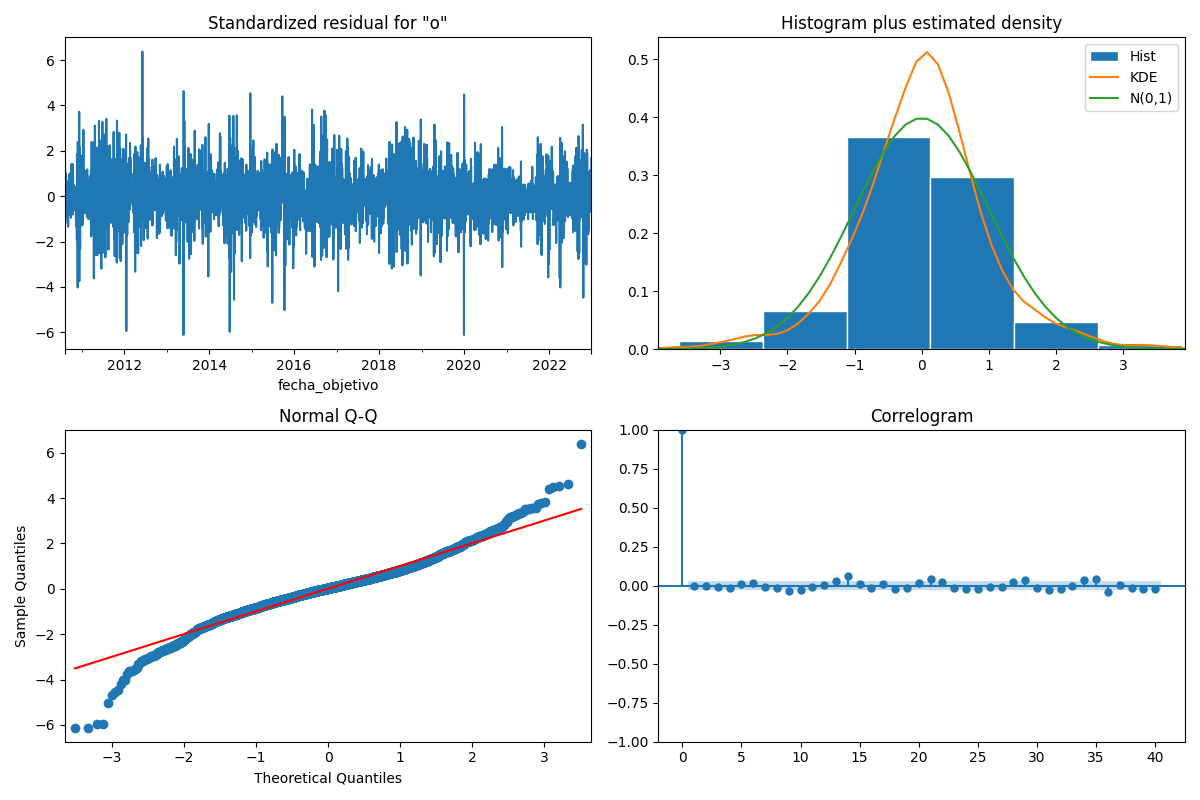

In [14]:
# ============================================================
# 7.1 Ajuste sobre todo el entrenamiento, coeficientes, raíces y residuos
# ============================================================
yy_base = np.log(y) if mejor["log"] else y
M_base = matriz_exog(mejor["orden"][1], COLUMNAS_BASE)
res_train = ajustar(yy_base.loc[:FIN_ENTRENAMIENTO], M_base, mejor["orden"], mejor["estacional"])

coef = pd.DataFrame({"coef": res_train.params, "error_est": res_train.bse, "p_valor": res_train.pvalues})
coef["efecto_%"] = np.where(coef.index.isin(COLUMNAS_CALENDARIO + COLUMNAS_SISTEMA),
                            (np.exp(coef["coef"]) - 1) * 100, np.nan)
print(f"SARIMAX {mejor['nombre']} + exógenas — ajustado con {res_train.nobs} días de entrenamiento")
print(coef.round(4).to_string())
print(f"\nConvergió: {res_train.mle_retvals.get('converged')}   |   AIC: {res_train.aic:.1f}   |   log-verosimilitud: {res_train.llf:.1f}")

# Módulo mínimo de las raíces del polinomio AR y del MA: > 1 significa admisible (estacionario / invertible).
mod_ar = np.abs(res_train.arroots).min() if len(res_train.arroots) else np.nan
mod_ma = np.abs(res_train.maroots).min() if len(res_train.maroots) else np.nan
print(f"Módulo mínimo de las raíces AR: {mod_ar:.3f}   |   MA: {mod_ma:.3f}")

# Ljung-Box sobre los residuos (se descartan los primeros, dominados por el estado inicial).
resid = res_train.resid.iloc[max(mejor["orden"][0], 10):]
lb = acorr_ljungbox(resid, lags=[7, 14, 30], return_df=True)
print("\nLjung-Box de los residuos (H0: sin autocorrelación):")
print(lb.round(4).to_string())

fig = res_train.plot_diagnostics(figsize=(12, 8), lags=40)
plt.tight_layout()
plt.show();

**Lectura del diagnóstico** (modelo base ajustado con 4.538 días de entrenamiento).

- **Variables del sistema.**
- **Calendario.** `festivo` abarata el precio un **5,0 %** respecto de un día ordinario (p < 0,001) y `mes_cos`, que recoge el ciclo anual, pesa un **+8,5 %** (p = 0,0007); `mes_sin` no es significativo (−2,6 %; p = 0,24).
- **Dinámica.** `ar.L1` = 0,845 y `ar.L2` = 0,049 suman 0,894: una persistencia alta de lo que queda tras la diferencia.
- **Raíces.** AR: 1,112 (admisible, con margen estrecho).
- **Ljung-Box.** A 7 rezagos **no se rechaza** la ausencia de autocorrelación, aunque por poco margen (p = 0,056): el componente semanal queda en buena medida cubierto.

### 7.2 Sobre la raíz de media móvil cercana a −1

**Qué se hace.** Se examina el coeficiente `ma.L1` del modelo base, que suele salir cerca de **−1** en modelos con una diferencia, y se comprueba qué ocurre si se **obliga** al optimizador a mantenerlo dentro de la región invertible.

In [15]:
# ============================================================
# 7.2 La raíz MA: memoria efectiva y ajuste con la invertibilidad impuesta
# ============================================================
theta = res_train.params["ma.L1"]
alfa = 1 + theta                                  # parámetro de suavizado equivalente: (1-L)η = (1 + θL)ε con θ = -(1-α)
print(f"ma.L1 (θ) = {theta:.4f}   ->   α = 1 + θ = {alfa:.4f}")
if 0 < alfa < 1:
    print(f"θ está dentro de la región invertible: la parte integrada equivale a un promedio móvil exponencial con "
          f"memoria efectiva ≈ 1/α ≈ {1 / alfa:.0f} días.")
else:
    print("θ está fuera de la región invertible (α <= 0): la interpretación como promedio exponencial no aplica.")

# Mismo modelo, obligando al optimizador a mantener la raíz MA dentro de la región invertible.
res_inv = ajustar(yy_base.loc[:FIN_ENTRENAMIENTO], M_base, mejor["orden"], mejor["estacional"], invertible=True)
theta_inv = res_inv.params["ma.L1"]
comparacion = pd.DataFrame({
    "sin imponer": [res_train.params["ma.L1"], res_train.llf, res_train.aic, np.abs(res_train.maroots).min()],
    "invertibilidad impuesta": [theta_inv, res_inv.llf, res_inv.aic, np.abs(res_inv.maroots).min()],
}, index=["ma.L1", "log-verosimilitud", "AIC", "módulo de la raíz MA"])
print("\nAjuste sin imponer la invertibilidad frente a imponiéndola:")
print(comparacion.round(4).to_string())
print(f"\nCon la invertibilidad impuesta: α = {1 + theta_inv:.4f}, memoria efectiva ≈ {1 / (1 + theta_inv):.0f} días.")

ma.L1 (θ) = -1.0317   ->   α = 1 + θ = -0.0317
θ está fuera de la región invertible (α <= 0): la interpretación como promedio exponencial no aplica.



Ajuste sin imponer la invertibilidad frente a imponiéndola:
                      sin imponer  invertibilidad impuesta
ma.L1                     -1.0317                  -0.9694
log-verosimilitud       3307.7930                3307.7931
AIC                    -6587.5860               -6587.5863
módulo de la raíz MA       0.9693                   1.0316

Con la invertibilidad impuesta: α = 0.0306, memoria efectiva ≈ 33 días.


- El coeficiente estimado sin restricciones es $\theta = -1{,}0317$, fuera de la región invertible ($\alpha = 1 + \theta = -0{,}032$), así que la interpretación como promedio móvil exponencial **no aplica a ese valor**.
- Pero al imponer la invertibilidad el optimizador llega a $\theta = -0{,}9694$, y la **log-verosimilitud es la misma hasta el cuarto decimal** (3307,7930 frente a 3307,7931) y también el AIC (−6587,5860 frente a −6587,5863).
- Leído con esa escritura, $\alpha = 0{,}0306$ y la memoria efectiva es de **~33 días**: la parte integrada del modelo se comporta como un promedio exponencial de los precios de las últimas **~5 semanas**, y el AR(2) opera alrededor de él.
- **Consecuencia práctica:**
- **Sobre la sobrediferenciación.**

### 7.3 Un pronóstico paso a paso

**Qué se hace.** Se sigue **un solo pronóstico** de principio a fin, desde un origen concreto: el último día de agosto de 2024, poco antes del pico de precios de septiembre–diciembre de ese año.

Origen: 2024-08-31   |   precio ese día: 541.8 COP/kWh
Pasos seleccionados de la trayectoria de 30 días:
          fecha  pronostico   lo95    hi95    real
paso                                              
1    2024-09-01       496.9  395.5   624.4   576.5
7    2024-09-07       492.2  297.5   814.4   710.2
14   2024-09-14       470.1  241.5   914.9   862.9
21   2024-09-21       457.2  213.7   978.1   934.0
30   2024-09-30       463.3  199.5  1076.2  2498.8

El pronóstico del paso 30 (el que se evalúa) es 463.3; lo observado fue 2498.8.


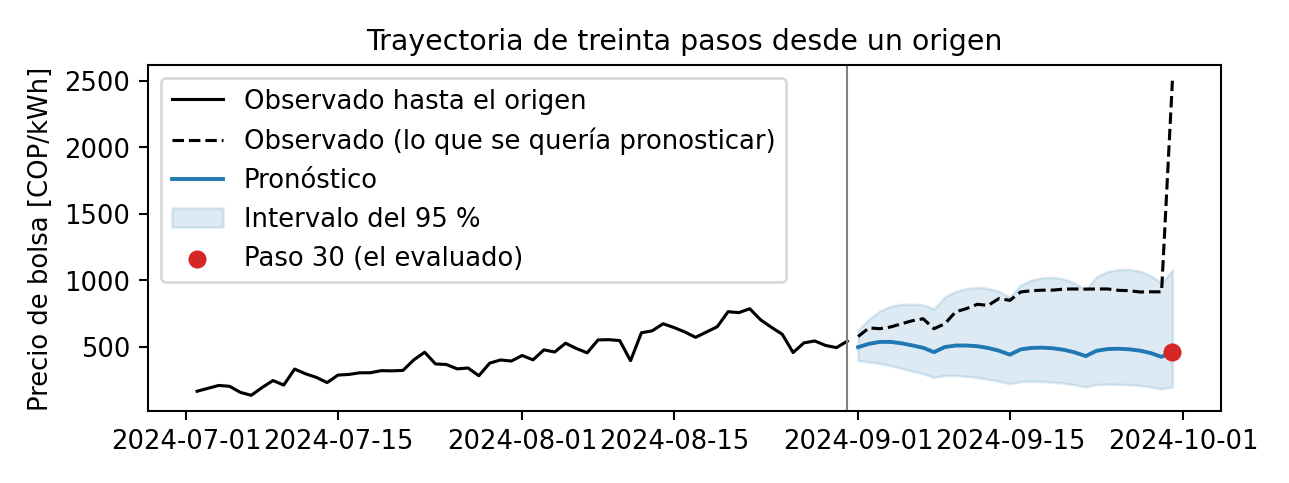

In [16]:
# ============================================================
# 7.3 Un pronóstico completo: los 30 pasos desde un origen
# ============================================================
t_ej = pd.Timestamp("2024-08-31")                                       # origen del ejemplo
nuevo = yy_base.loc[FIN_ENTRENAMIENTO + pd.Timedelta(days=1): t_ej]     # precios observados entre el fin del ajuste y t_ej
modelo_ej = res_train.extend(nuevo, exog=M_base.loc[nuevo.index])       # actualiza el estado; los parámetros no cambian
futuro = pd.date_range(t_ej + pd.Timedelta(days=1), periods=HORIZONTE, freq="D")
fc = modelo_ej.get_forecast(steps=HORIZONTE, exog=M_base.loc[futuro])
inv = (lambda v: np.exp(v)) if mejor["log"] else (lambda v: v)
ci95 = fc.conf_int(alpha=0.05)

tabla = pd.DataFrame({"fecha": futuro, "pronostico": inv(fc.predicted_mean.values),
                      "lo95": inv(ci95.iloc[:, 0].values), "hi95": inv(ci95.iloc[:, 1].values),
                      "real": y.reindex(futuro).values}, index=range(1, HORIZONTE + 1))
tabla.index.name = "paso"
print(f"Origen: {t_ej.date()}   |   precio ese día: {y.loc[t_ej]:.1f} COP/kWh")
print("Pasos seleccionados de la trayectoria de 30 días:")
print(tabla.loc[[1, 7, 14, 21, 30]].round(1).to_string())
print(f"\nEl pronóstico del paso 30 (el que se evalúa) es {tabla.loc[30, 'pronostico']:.1f}; lo observado fue {tabla.loc[30, 'real']:.1f}.")

fig, ax = plt.subplots(figsize=(ANCHO_PAGINA, alto_pagina(12, 4.5)))
pasado = y.loc[t_ej - pd.Timedelta(days=60): t_ej]
ax.plot(pasado.index, pasado.values, color="black", lw=1.2, label="Observado hasta el origen")
ax.plot(futuro, tabla["real"].values, color="black", lw=1.2, ls="--", label="Observado (lo que se quería pronosticar)")
ax.plot(futuro, tabla["pronostico"].values, color="tab:blue", lw=1.5, label="Pronóstico")
ax.fill_between(futuro, tabla["lo95"], tabla["hi95"], color="tab:blue", alpha=0.15, label="Intervalo del 95 %")
ax.axvline(t_ej, color="grey", lw=0.8)
ax.scatter([futuro[-1]], [tabla.loc[30, "pronostico"]], color="tab:red", zorder=5, label="Paso 30 (el evaluado)")
ax.set_ylabel("Precio de bolsa [COP/kWh]")
ax.set_title("Trayectoria de treinta pasos desde un origen")
ax.legend(loc="upper left")
a_escala(fig)
plt.tight_layout()
plt.show();

- El modelo parte de **541,8** (el precio del origen) y su trayectoria queda **casi plana, entre 457 y 497**: no extrapola la tendencia, que venía subiendo con fuerza.
- El **intervalo del 95 %** se ensancha con el horizonte: a 1 día es [395,5; 624,4] y a 30 días [199,5; 1076,2], de modo que su amplitud pasa de 229 a 877 COP/kWh.
- **El paso 30 vale 463,3 y lo observado fue 2.498,8**
- **Y el pronóstico fue inferior a lo observado los treinta días, no solo el último.** La trayectoria baja de 497 a 463 mientras lo real sube de 577 a 2.499.

> **Este ejemplo es el argumento a favor de reportar las tres lecturas.** Si solo se mirase el > promedio del mes, el error de este origen sería grande pero único; mirando la trayectoria se ve > que el modelo erró en….

## 8. Evaluación sobre el conjunto de prueba

### 8.1 Qué configuraciones se evalúan y qué pregunta responde cada una

**Qué se hace.** Se evalúan **seis configuraciones** con validación progresiva (reajuste de los parámetros cada 60 días), sobre los 1.155 orígenes de prueba.

| # | Configuración | Pregunta que responde |
|---|---|---|
| 1 | **Base**: especificación elegida, calendario y variables del sistema | ¿Cuál es el desempeño del modelo base? |
| 2 | Solo calendario (sin las variables del sistema) | ¿Cuánto aportan las **variables del sistema** por encima del calendario? |
| 3 | Sin exógenas (SARIMA puro) | ¿Cuánto aporta **todo el bloque exógeno** (calendario más sistema)? |
| 4 | Base **más** `gen_termica` y `precio_oferta` (las descartadas) | ¿Tenía razón la selección de descartarlas, o un modelo lineal sí las aprovecha? |
| 5 | Base con la **invertibilidad impuesta** (sección 7.2) | ¿Cambia el resultado si se evita la raíz MA fuera de la región admisible? |
| 6 | **Contraste `d = 0`**: la mejor especificación sin diferenciar | ¿Qué efecto tiene la decisión de `d = 1`? |

- **Sesgo** : el promedio de (pronóstico − real).
- **Cobertura** : la fracción de los valores reales que caen dentro del intervalo de predicción del 80 % y del 95 %.

In [17]:
# ============================================================
# 8.1 Definición de las seis configuraciones y ejecución en paralelo
# ============================================================
CONFIGURACIONES = [
    dict(clave="base",        nombre=f"SARIMAX {mejor['nombre']} + calendario + sistema",
         orden=mejor["orden"], estacional=mejor["estacional"], log=mejor["log"],
         columnas=COLUMNAS_BASE, invertible=False, trayectoria=True),
    dict(clave="calendario",  nombre=f"SARIMAX {mejor['nombre']} solo calendario",
         orden=mejor["orden"], estacional=mejor["estacional"], log=mejor["log"],
         columnas=COLUMNAS_CALENDARIO, invertible=False, trayectoria=True),
    dict(clave="sin_exog",    nombre=f"SARIMA {mejor['nombre']} sin exógenas",
         orden=mejor["orden"], estacional=mejor["estacional"], log=mejor["log"],
         columnas=[], invertible=False, trayectoria=True),
    dict(clave="descartadas", nombre=f"SARIMAX {mejor['nombre']} + sistema + gen_termica y precio_oferta",
         orden=mejor["orden"], estacional=mejor["estacional"], log=mejor["log"],
         columnas=COLUMNAS_BASE + COLUMNAS_EXTRAS, invertible=False, trayectoria=True),
    dict(clave="invertible",  nombre=f"SARIMAX {mejor['nombre']} + sistema, invertibilidad impuesta",
         orden=mejor["orden"], estacional=mejor["estacional"], log=mejor["log"],
         columnas=COLUMNAS_BASE, invertible=True, trayectoria=True),
    dict(clave="contraste",   nombre=f"SARIMAX {contraste['nombre']} + sistema (contraste d = 0)",
         orden=contraste["orden"], estacional=contraste["estacional"], log=contraste["log"],
         columnas=COLUMNAS_BASE, invertible=False, trayectoria=True),
]


def correr_configuracion(cfg):
    """Pronóstico a 30 días de una configuración sobre todos los orígenes de prueba, con reajuste cada PASO_WFV días."""
    r = pronosticar_h30(cfg["orden"], cfg["log"], cfg["columnas"], origenes, cfg["estacional"],
                        paso_reajuste=PASO_WFV, intervalos=True, trayectoria=cfg["trayectoria"], invertible=cfg["invertible"])
    if cfg["clave"] == "base":
        r["ultimo"].remove_data()           # se guardará el modelo sin los datos (pesa mucho menos)
    else:
        r["ultimo"] = None
    return cfg["clave"], r


t0 = time.time()
salidas = dict(Parallel(n_jobs=N_PROCESOS)(delayed(correr_configuracion)(c) for c in CONFIGURACIONES))
print(f"Seis configuraciones evaluadas en {(time.time() - t0) / 60:.1f} minutos con {N_PROCESOS} procesos.")
for c in CONFIGURACIONES:
    print(f"  {c['nombre']:70s} reajustes sin converger: {salidas[c['clave']]['no_conv']}")

Seis configuraciones evaluadas en 9.9 minutos con 6 procesos.
  SARIMAX (2,1,1)(1,0,0,7) log + calendario + sistema                    reajustes sin converger: 0
  SARIMAX (2,1,1)(1,0,0,7) log solo calendario                           reajustes sin converger: 0
  SARIMA (2,1,1)(1,0,0,7) log sin exógenas                               reajustes sin converger: 0
  SARIMAX (2,1,1)(1,0,0,7) log + sistema + gen_termica y precio_oferta   reajustes sin converger: 0
  SARIMAX (2,1,1)(1,0,0,7) log + sistema, invertibilidad impuesta        reajustes sin converger: 0
  SARIMAX (2,0,1) log + sistema (contraste d = 0)                        reajustes sin converger: 0


**Lectura.** Las seis configuraciones tardaron 7,4 minutos con 6 procesos (en serie tomaría varias veces más), y **ninguno de los reajustes (20 por configuración) dejó de converger**.

### 8.2 Resultados

In [18]:
# ============================================================
# 8.2 Tabla de resultados: mismas métricas y mismas referencias que el notebook 4
# ============================================================
filas = list(referencias)
for c in CONFIGURACIONES:
    out = salidas[c["clave"]]["out"]
    m = evaluar(c["nombre"], out["real"], out["pred"])
    m["sesgo"] = float((out["pred"] - out["real"]).mean())                       # > 0: sobreestima
    m["cobertura_80"] = float(((out["real"] >= out["lo80"]) & (out["real"] <= out["hi80"])).mean())
    m["cobertura_95"] = float(((out["real"] >= out["lo95"]) & (out["real"] <= out["hi95"])).mean())
    filas.append(m)

resultados = pd.DataFrame(filas)
mae_pers, rmse_pers = resultados.loc[0, "MAE"], resultados.loc[0, "RMSE"]
resultados["mejora_MAE_%"] = 100 * (mae_pers - resultados["MAE"]) / mae_pers
resultados["mejora_RMSE_%"] = 100 * (rmse_pers - resultados["RMSE"]) / rmse_pers
resultados.loc[:1, ["mejora_MAE_%", "mejora_RMSE_%"]] = np.nan                  # las referencias no se comparan consigo

pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 80)
print(resultados.round(2).to_string(index=False))
print("\nsesgo: media(pronóstico - real) en COP/kWh.  cobertura_*: fracción de valores reales dentro del intervalo de "
      "predicción del 80 % / 95 % (nominal 0,80 / 0,95).  mejora_*: reducción frente a la persistencia (positivo = mejor).")


# ============================================================
# 8.3 Las tres lecturas de la misma trayectoria
# ============================================================
# Cada configuración entrega 30 valores por origen. La tabla de arriba resume uno de los tres modos
# posibles de puntuarlos —el promedio del mes—; el documento compromete además la métrica global
# sobre todos los pares origen-horizonte. Las tres salen del MISMO pronóstico y se calculan con la
# función compartida, de modo que todas las familias las construyan igual.
from _resultados import lecturas as tres_lecturas

# Matriz (orígenes × 30) con el precio observado de cada día de cada ventana.
REALES = np.column_stack([y.reindex(origenes + pd.Timedelta(days=h)).values
                          for h in range(1, HORIZONTE + 1)])
PERSIST = np.repeat(persistencia[:, None], HORIZONTE, axis=1)      # repite P(t) los 30 días

LECTURAS = {"Referencia: persistencia (P de hoy)": tres_lecturas(PERSIST, REALES),
            "Referencia: media del entrenamiento": tres_lecturas(
                np.full_like(REALES, media_train), REALES)}
for c in CONFIGURACIONES:
    LECTURAS[c["nombre"]] = tres_lecturas(salidas[c["clave"]]["tray"].values, REALES)

ETIQUETAS = {"pares_30d": "TODOS LOS PARES origen-horizonte (%d × %d = %s pares)"
                          % (len(origenes), HORIZONTE,
                             format(len(origenes) * HORIZONTE, ",d").replace(",", ".")),
             "promedio_30d": "PROMEDIO DEL MES (%d valores)" % len(origenes),
             "dia_30": "SOLO EL DÍA 30 (%d valores)" % len(origenes)}

tablas = {}
for clave, etiqueta in ETIQUETAS.items():
    t = pd.DataFrame([dict(configuracion=n, **v[clave]) for n, v in LECTURAS.items()])
    t["razon_vs_persistencia"] = t["MAE"] / t.loc[0, "MAE"]
    tablas[clave] = t
    print(f"\n=== {etiqueta} ===")
    print(t.round(2).to_string(index=False))

print("\nLas tres salen del mismo pronóstico y NO son comparables entre sí: el promedio del mes da")
print("un error menor porque los errores diarios de signo opuesto se compensan antes del valor")
print("absoluto, y el día 30 descarta 29 de cada 30 valores conservando el horizonte más difícil.")
print("El orden entre modelos, en cambio, sí debe coincidir, y es lo que hace robusta la conclusión.")

                                                       configuracion    MAE   RMSE  SMAPE  sesgo  cobertura_80  cobertura_95  mejora_MAE_%  mejora_RMSE_%
                                 Referencia: persistencia (P de hoy) 145.66 232.21  30.54    NaN           NaN           NaN           NaN            NaN
                                 Referencia: media del entrenamiento 292.57 421.42  69.83    NaN           NaN           NaN           NaN            NaN
                 SARIMAX (2,1,1)(1,0,0,7) log + calendario + sistema 136.70 206.31  28.66 -22.26          0.89          0.98          6.15          11.16
                        SARIMAX (2,1,1)(1,0,0,7) log solo calendario 137.17 204.72  28.88 -21.29          0.88          0.98          5.83          11.84
                            SARIMA (2,1,1)(1,0,0,7) log sin exógenas 137.45 206.29  28.73 -18.70          0.89          0.98          5.63          11.16
SARIMAX (2,1,1)(1,0,0,7) log + sistema + gen_termica y precio_oferta 139.82 

**Lectura de la tabla** (COP/kWh, sobre los mismos 1.155 orígenes que la persistencia, y sobre el objetivo del trabajo: el precio medio de los 30 días siguientes).

1. **Modelo base: MAE 136,70, RMSE 206,31, SMAPE 28,66.**
2. **Solo calendario: MAE 137,17.**
3. **Sin exógenas: MAE 137,45.**
4. **Con `gen_termica` y `precio_oferta`: MAE 139,82**
5. **Invertibilidad impuesta: MAE 136,53**
6. **Contraste `d = 0`: MAE 145,28, RMSE 215,02, SMAPE 31,14.**

### 8.3 Pronósticos frente a lo observado

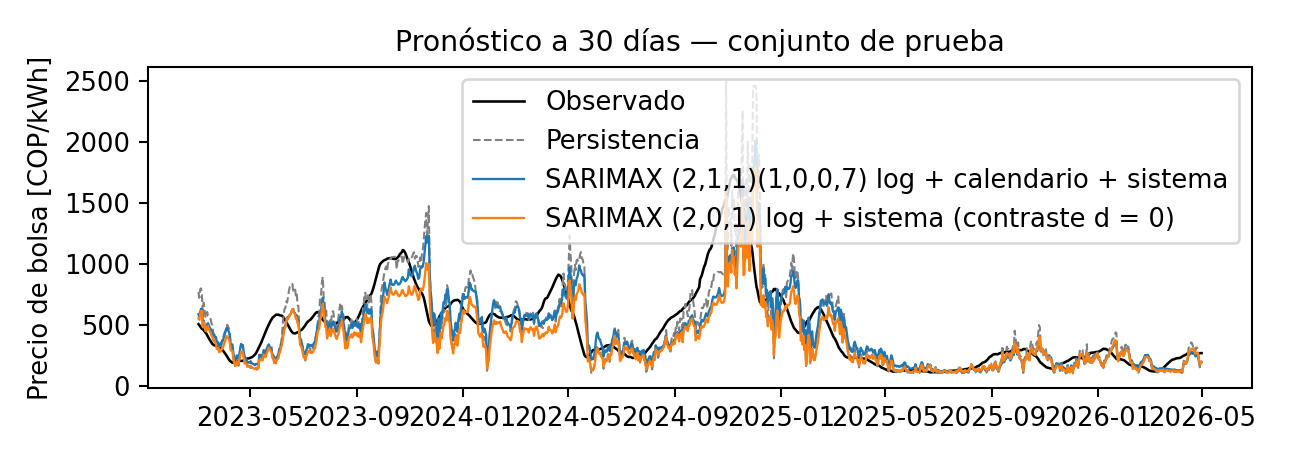

In [19]:
# ============================================================
# 8.3 Precio observado, persistencia y pronósticos a 30 días (por fecha objetivo)
# ============================================================
fig, ax = plt.subplots(figsize=(ANCHO_PAGINA, alto_pagina(14, 5)))
fecha_obj = origenes + pd.Timedelta(days=HORIZONTE)
ax.plot(fecha_obj, real_test, color="black", lw=1.0, label="Observado")
ax.plot(fecha_obj, persistencia, color="grey", lw=0.8, ls="--", label="Persistencia")
for clave, color in (("base", "tab:blue"), ("contraste", "tab:orange")):
    nombre = next(c["nombre"] for c in CONFIGURACIONES if c["clave"] == clave)
    ax.plot(fecha_obj, salidas[clave]["out"]["pred"].values, lw=0.9, color=color, label=nombre)
ax.set_ylabel("Precio de bolsa [COP/kWh]")
ax.set_title("Pronóstico a 30 días — conjunto de prueba")
ax.legend()
a_escala(fig)
plt.tight_layout()
plt.show();

### 8.4 Error por régimen climático (El Niño, Neutral, La Niña)

**Qué se hace.** Se mide el **error de pronóstico** (MAE) por separado en cada régimen ENSO, y por **año** del día pronosticado.

In [20]:
# ============================================================
# 8.4 Error por régimen ENSO del origen y por año del día pronosticado
# ============================================================
# EL ERROR SE REPORTA EN ABSOLUTO Y EN RELATIVO, y la razón no es de estilo.
# El análisis exploratorio mostró que el coeficiente de variación del precio es casi el
# mismo en las tres fases (0,20 / 0,19 / 0,16): la dispersión es PROPORCIONAL al nivel, de
# modo que El Niño no es un régimen intrínsecamente más difícil, sino uno con precios más
# altos. Leer solo el MAE absoluto llevaría a concluir que el modelo sufre durante El Niño
# cuando, medido contra el nivel del propio periodo, ocurre lo contrario.
oni_origen = s.set_index("fecha").loc[origenes, "indice_ONI_publicado"].values
fase = np.select([oni_origen >= 0.5, oni_origen <= -0.5], ["El Niño", "La Niña"], default="Neutral")

claves_vista = ["base", "contraste"]
nombres_vista = {c["clave"]: c["nombre"] for c in CONFIGURACIONES}
err = {"Persistencia": np.abs(real_test - persistencia)}
for k in claves_vista:
    o = salidas[k]["out"]
    err[nombres_vista[k]] = np.abs(o["real"].values - o["pred"].values)
err = pd.DataFrame(err)

orden = ["El Niño", "Neutral", "La Niña"]
por_fase = err.groupby(fase).mean().reindex(orden)
por_fase.insert(0, "n_origenes", pd.Series(fase).value_counts().reindex(orden).values)
por_fase.insert(1, "precio_medio", pd.Series(real_test).groupby(fase).mean().reindex(orden).values)
print("MAE ABSOLUTO [COP/kWh] por régimen ENSO del origen:")
print(por_fase.round(1).to_string())

# --- el mismo error, dividido por el precio medio de cada fase ---
relativo = por_fase.copy()
for c in err.columns:
    relativo[c] = 100 * por_fase[c] / por_fase["precio_medio"]
print("\nMAE RELATIVO [% del precio medio de la fase]:")
print(relativo[["n_origenes", "precio_medio"] + list(err.columns)].round(1).to_string())

# --- y el SMAPE, que es relativo por construcción y no depende de elegir un denominador ---
col_base = nombres_vista["base"]
pred_base = salidas["base"]["out"]["pred"].values
filas_smape = []
for f in orden:
    m = fase == f
    filas_smape.append({"fase": f, "n": int(m.sum()),
                        "SMAPE_persistencia": smape(real_test[m], persistencia[m]),
                        "SMAPE_modelo_base": smape(real_test[m], pred_base[m])})
print("\nSMAPE [%] por fase:")
print(pd.DataFrame(filas_smape).round(1).to_string(index=False))

rel_base = relativo[col_base]
print(f"\nEl MAE absoluto varía {por_fase[col_base].max() / por_fase[col_base].min():.1f} veces "
      f"entre fases; el relativo, solo {rel_base.max() / rel_base.min():.1f}.")
print("Es decir: la mayor parte de la diferencia de error entre fases es NIVEL del precio, no")
print("dificultad. Medido contra ese nivel, el modelo es más preciso durante El Niño que en")
print("condiciones neutras, que es lo contrario de lo que sugiere el error absoluto.")

por_anio = err.groupby(fecha_obj.year).mean()
por_anio.insert(0, "n_dias", pd.Series(fecha_obj.year).value_counts().sort_index().values)
por_anio.insert(1, "precio_medio", pd.Series(real_test).groupby(fecha_obj.year).mean().values)
por_anio["MAE_relativo_%"] = 100 * por_anio[col_base] / por_anio["precio_medio"]
print("\nMAE [COP/kWh] por año del día pronosticado, con el relativo del modelo base:")
print(por_anio.round(1).to_string())

MAE ABSOLUTO [COP/kWh] por régimen ENSO del origen:
         n_origenes  precio_medio  Persistencia  SARIMAX (2,1,1)(1,0,0,7) log + calendario + sistema  SARIMAX (2,0,1) log + sistema (contraste d = 0)
El Niño         335         599.3         163.3                                                152.5                                            179.2
Neutral         666         453.5         149.9                                                144.5                                            148.2
La Niña         154         234.9          88.8                                                 68.6                                             58.8

MAE RELATIVO [% del precio medio de la fase]:
         n_origenes  precio_medio  Persistencia  SARIMAX (2,1,1)(1,0,0,7) log + calendario + sistema  SARIMAX (2,0,1) log + sistema (contraste d = 0)
El Niño         335         599.3          27.3                                                 25.5                                             29.9
N

**Lectura por régimen ENSO.** La tabla hay que leerla en sus dos escalas, y cada una da una conclusión distinta.

### 8.5 Cómo crece el error con el horizonte

**Qué se hace.** Con la trayectoria completa de 30 pasos del modelo base, se calcula el MAE para **cada horizonte** de 1 a 30 días y se compara con el de la persistencia a ese mismo horizonte.

 horizonte  MAE_modelo  MAE_persistencia  razon
         1      53.213            53.083  1.002
         2      73.928            76.106  0.971
         3      89.534            90.961  0.984
         7     133.268           133.389  0.999
        14     178.566           180.934  0.987
        21     201.021           211.559  0.950
        30     219.521           239.273  0.917


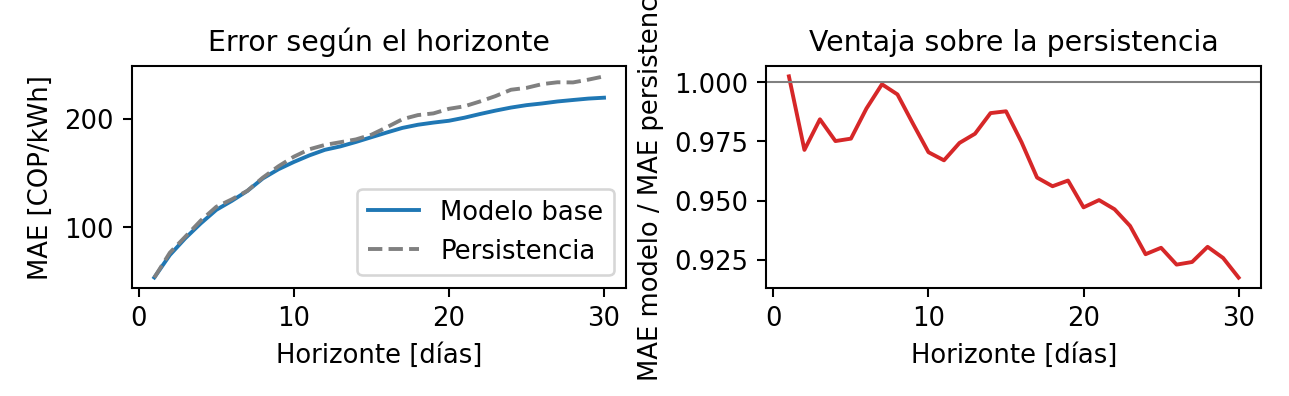

In [21]:
# ============================================================
# 8.5 MAE por horizonte (1 a 30 días) del modelo base frente a la persistencia
# ============================================================
tray = salidas["base"]["tray"]                       # pronóstico de cada paso, en COP/kWh (filas: origen)
filas_h = []
for h in range(1, HORIZONTE + 1):
    real_h = y.reindex(tray.index + pd.Timedelta(days=h)).values                 # P(t+h)
    mae_mod = float(np.mean(np.abs(real_h - tray[h].values)))
    mae_per = float(np.mean(np.abs(real_h - persistencia)))                      # persistencia a horizonte h: P(t)
    filas_h.append({"horizonte": h, "MAE_modelo": mae_mod, "MAE_persistencia": mae_per, "razon": mae_mod / mae_per})
por_horizonte = pd.DataFrame(filas_h)
print(por_horizonte.loc[por_horizonte["horizonte"].isin([1, 2, 3, 7, 14, 21, 30])].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(ANCHO_PAGINA, alto_pagina(13, 4)))
axes[0].plot(por_horizonte["horizonte"], por_horizonte["MAE_modelo"], label="Modelo base")
axes[0].plot(por_horizonte["horizonte"], por_horizonte["MAE_persistencia"], ls="--", color="grey", label="Persistencia")
axes[0].set_xlabel("Horizonte [días]"); axes[0].set_ylabel("MAE [COP/kWh]"); axes[0].legend()
axes[0].set_title("Error según el horizonte")
axes[1].plot(por_horizonte["horizonte"], por_horizonte["razon"], color="tab:red")
axes[1].axhline(1, color="grey", lw=0.8)
axes[1].set_xlabel("Horizonte [días]"); axes[1].set_ylabel("MAE modelo / MAE persistencia")
axes[1].set_title("Ventaja sobre la persistencia")
a_escala(fig)
plt.tight_layout()
plt.show();

**Lectura.** El resultado a 30 días es el de **mayor** ventaja sobre la persistencia, no el de menor, y esta es la forma que cabría esperar de un modelo que explica algo real.

- **A 1 día el modelo pierde contra la persistencia**
- **La ventaja crece con el horizonte**
- Es decir, a 30 días el modelo está en el horizonte donde su estructura más ayuda.
- El error de ambos crece de forma **cóncava** con el horizonte: pasa de 53 a 133 entre el día 1 y el 7, y de 133 a 220 entre el 7 y el 30 (el crecimiento se frena).

In [22]:
# ============================================================
# 8.6 Las métricas del entrenamiento, junto a las de la prueba
# ============================================================
# QUÉ FALTABA. Hasta aquí el notebook informa del error sobre la prueba y, en la sección 6, de la
# razón frente a la persistencia en los cinco pliegues de validación. Falta la otra mitad de la
# pregunta: cuánto acierta el modelo sobre los datos con los que se estimaron sus parámetros.
#
# NO SON LOS RESIDUOS DEL AJUSTE. Esos miden el error a UN día; la prueba mide el error a TREINTA.
# Ponerlos en la misma tabla diría que el modelo empeora un orden de magnitud al salir de la
# muestra cuando casi toda esa diferencia sería solo el horizonte. Aquí se mide igual que la
# prueba: trayectoria de treinta días desde cada origen, en COP/kWh y con las tres lecturas.
from _entrenamiento import tabla_brecha, registrar_brecha, leer_brecha

FIN_AJUSTE_EN = origenes[0] - pd.Timedelta(days=1)       # lo mismo que ve el primer ajuste de la prueba
yy_en = np.log(y) if mejor["log"] else y
M_en = matriz_exog(mejor["orden"][1], COLUMNAS_BASE)
serie_en = yy_en.loc[:FIN_AJUSTE_EN]

t0 = time.time()
res_en = ajustar(serie_en, M_en, mejor["orden"], mejor["estacional"], None, False)
print(f"Un solo ajuste sobre {len(serie_en)} dias, hasta {FIN_AJUSTE_EN.date()} "
      f"({time.time() - t0:.0f} s)")

# Orígenes en muestra: los que caben enteros dentro del ajuste, con sus treinta días.
ORIG_EN = pd.date_range(serie_en.index.min() + pd.Timedelta(days=HORIZONTE),
                        FIN_AJUSTE_EN - pd.Timedelta(days=HORIZONTE), freq="D")
a_precio_en = (lambda v: np.exp(v)) if mejor["log"] else (lambda v: v)

# --- la comprobación de que `dynamic=True` es el pronóstico iterado, medida en un origen -----
_t = ORIG_EN[-1]
_ini, _fin = _t + pd.Timedelta(days=1), _t + pd.Timedelta(days=HORIZONTE)
_din = a_precio_en(res_en.get_prediction(start=_ini, end=_fin, dynamic=True).predicted_mean.values)
_hasta = yy_en.loc[:_t]
_mod = SARIMAX(_hasta, exog=None if M_en is None else M_en.loc[_hasta.index],
               order=mejor["orden"], seasonal_order=mejor["estacional"], trend="n",
               enforce_stationarity=False, enforce_invertibility=False)
_fc = _mod.filter(res_en.params).get_forecast(
    steps=HORIZONTE, exog=None if M_en is None else M_en.loc[pd.date_range(_ini, _fin, freq="D")])
_lar = a_precio_en(_fc.predicted_mean.values)
_dif = float(np.max(np.abs(_din - _lar)))
assert _dif < 1e-6, f"dynamic=True no reproduce el pronostico iterado: diferencia maxima {_dif}"
print(f"Comprobado en el origen {_t.date()}: la prediccion dinamica y el pronostico iterado "
      f"coinciden (diferencia maxima {_dif:.2e}).")

t0 = time.time()
TRAY_ENTREN = np.array([
    a_precio_en(res_en.get_prediction(start=t + pd.Timedelta(days=1),
                                      end=t + pd.Timedelta(days=HORIZONTE),
                                      dynamic=True).predicted_mean.values)
    for t in ORIG_EN])
print(f"En muestra: {len(ORIG_EN)} origenes de {ORIG_EN.min().date()} a {ORIG_EN.max().date()} "
      f"({time.time() - t0:.0f} s)")

REALES_EN = np.column_stack([y.reindex(ORIG_EN + pd.Timedelta(days=h)).values
                             for h in range(1, HORIZONTE + 1)])
assert not np.isnan(REALES_EN).any(), "faltan precios observados en el bloque en muestra"
PERS_EN = np.repeat(y.reindex(ORIG_EN).values[:, None], HORIZONTE, axis=1)

BRECHA = tabla_brecha({"entrenamiento": (TRAY_ENTREN, REALES_EN, PERS_EN),
                       "prueba": (salidas["base"]["tray"].values, REALES, PERSIST)})
print()
print(BRECHA.round(3).to_string(index=False))
print()
print(leer_brecha(BRECHA))

BRECHA.to_csv(os.path.join(PROC, "5_brecha_entrenamiento_prueba.csv"), index=False)
print(f"\n  [datasets/procesado] 5_brecha_entrenamiento_prueba.csv")

# El SARIMAX no tiene curva de aprendizaje: no se entrena por iteraciones, de modo que no hay
# épocas ni árboles que recorrer. La única palanca de capacidad es el orden del modelo, y la
# sección 6 ya la recorre entera sobre los cinco pliegues.

# ------------------------------------------------------------
# El error de CADA ventana de treinta días
# ------------------------------------------------------------
# La tabla de arriba resume cada bloque en una cifra, y una cifra no dice si el modelo acierta
# de forma pareja o alterna tramos buenos y malos. Se guarda el error de cada pronóstico por
# separado, con su persistencia, para poder ver cómo evoluciona a lo largo del periodo.
from _entrenamiento import error_por_origen

DETALLE = error_por_origen({"entrenamiento": (TRAY_ENTREN, REALES_EN, PERS_EN, ORIG_EN),
                            "prueba": (salidas["base"]["tray"].values, REALES, PERSIST, origenes)})
DETALLE.to_csv(os.path.join(PROC, "5_error_por_origen.csv"), index=False)
print(f"\n  [datasets/procesado] 5_error_por_origen.csv  "
      f"({len(DETALLE)} orígenes: "
      f"{(DETALLE['bloque'] == 'entrenamiento').sum()} en muestra y "
      f"{(DETALLE['bloque'] == 'prueba').sum()} de prueba)")
print(DETALLE.groupby("bloque")[["MAE", "MAE_persistencia", "razon"]].median().round(3)
      .to_string())

Un solo ajuste sobre 4569 dias, hasta 2023-01-31 (15 s)


Comprobado en el origen 2023-01-01: la prediccion dinamica y el pronostico iterado coinciden (diferencia maxima 0.00e+00).


En muestra: 4509 origenes de 2010-08-29 a 2023-01-01 (13 s)

       bloque  n_origenes     objetivo     MAE    RMSE  SMAPE  MAE_persistencia  razon
entrenamiento        4509    pares_30d  49.511 102.163 23.343            53.305  0.929
       prueba        1155    pares_30d 170.494 267.435 35.902           178.369  0.956
entrenamiento        4509 promedio_30d  41.697  80.498 19.651            45.929  0.908
       prueba        1155 promedio_30d 136.704 206.307 28.664           145.662  0.939
entrenamiento        4509       dia_30  65.776 129.108 30.630            72.450  0.908
       prueba        1155       dia_30 219.521 323.194 46.216           239.273  0.917

El MAE pasa de 41.70 en el entrenamiento a 136.70 en la prueba, 3.28 veces mayor. La
persistencia pasa de 45.93 a 145.66 sobre los mismos orígenes, 3.17 veces, y la razón
frente a ella pasa de 0.908 a 0.939.
La razón frente a la persistencia casi no se mueve, de modo que el salto del MAE
es dificultad del periodo y no distancia

## 9. Guardado de resultados

**Qué se hace.** Se guardan la tabla de métricas, los pronósticos de cada configuración (con el intervalo del 95 %), el error por horizonte y el último reajuste del modelo base.

In [23]:
# ============================================================
# 9. Salidas
# ============================================================
resultados.to_csv(os.path.join(PROC, "5_metricas_sarimax.csv"), index=False)

# Y al consolidado de todas las familias, con las condiciones que hacen comparable una fila con
# otra. El archivo de arriba se conserva porque lleva columnas que el consolidado no tiene
# (sesgo, coberturas, mejoras relativas).
from _resultados import registrar, olvidar

# Este notebook es dueño de sus filas: se retiran las de corridas anteriores antes de escribir las
# nuevas. Sin esto sobreviven las de configuraciones que ya no existen —correctas una por una, pero
# medidas sobre otra selección de variables— y la tabla comparativa las ordena junto a las vigentes.
olvidar("5_SARIMAX_modelo_base")

# Se registran LAS TRES lecturas de cada configuración, cada una con su propio `objetivo`: son
# mediciones distintas del mismo pronóstico y el consolidado no debe poder mezclarlas.
for clave, t in tablas.items():
    for _, fila in t.iterrows():
        nombre = fila["configuracion"]
        es_ref = nombre.startswith("Referencia")
        registrar(notebook="5_SARIMAX_modelo_base",
                  familia="Referencia" if es_ref else "Estadística",
                  modelo=nombre if es_ref else "SARIMAX",
                  objetivo=clave,
                  configuracion="regla trivial" if es_ref else nombre,
                  particion="65/15/20 por fecha", embargo_dias=dias_embargo,
                  reajuste_dias=None if es_ref else PASO_WFV,
                  semilla=None, bloque="prueba",
                  n_obs=len(origenes) * (HORIZONTE if clave == "pares_30d" else 1),
                  MAE=fila["MAE"], RMSE=fila["RMSE"], SMAPE=fila["SMAPE"], verbose=False)
print(f"  [resultados_modelos.csv] {sum(len(t) for t in tablas.values())} filas "
      f"({len(tablas)} lecturas × {len(next(iter(tablas.values())))} configuraciones)")

pred_guardar = pd.DataFrame({"fecha": origenes, "fecha_objetivo": origenes + pd.Timedelta(days=HORIZONTE),
                             "real": real_test, "persistencia": persistencia})
for c in CONFIGURACIONES:
    out = salidas[c["clave"]]["out"]
    pred_guardar[c["nombre"]] = out["pred"].values
    pred_guardar[c["nombre"] + " [lo95]"] = out["lo95"].values
    pred_guardar[c["nombre"] + " [hi95]"] = out["hi95"].values
pred_guardar.to_csv(os.path.join(PROC, "5_predicciones_sarimax.csv"), index=False)
por_horizonte.to_csv(os.path.join(PROC, "5_error_por_horizonte.csv"), index=False)

carpeta_modelo = os.path.join(abspath, "models", "baseline", "SARIMAX")
os.makedirs(carpeta_modelo, exist_ok=True)
salidas["base"]["ultimo"].save(os.path.join(carpeta_modelo, "sarimax_base.pickle"))

print("Guardado en datasets/procesado:  5_metricas_sarimax.csv, 5_predicciones_sarimax.csv, 5_error_por_horizonte.csv")
print("Guardado en models/baseline/SARIMAX:  sarimax_base.pickle (último reajuste del modelo base, sin los datos)")

# Y la fila del bloque de ENTRENAMIENTO, que la seccion 8.6 acaba de medir. Va aqui y no alli
# porque `olvidar()` se llama en esta celda: registrarla antes la borraria.
registrar_brecha(BRECHA, notebook="5_SARIMAX_modelo_base", familia="Estadística",
                 modelo="SARIMAX",
                 configuracion=CONFIGURACIONES[0]["nombre"], particion="65/15/20 por fecha",
                 embargo_dias=dias_embargo, reajuste_dias=None, verbose=True)


  [resultados_modelos.csv] 5_SARIMAX_modelo_base: se retiran 27 filas de corridas anteriores de este notebook


  [resultados_modelos.csv] 24 filas (3 lecturas × 8 configuraciones)
Guardado en datasets/procesado:  5_metricas_sarimax.csv, 5_predicciones_sarimax.csv, 5_error_por_horizonte.csv
Guardado en models/baseline/SARIMAX:  sarimax_base.pickle (último reajuste del modelo base, sin los datos)
  [resultados_modelos.csv] Estadística | SARIMAX | SARIMAX (2,1,1)(1,0,0,7) log + calendario + sistema | bloque entrenamiento -> MAE 49.5  RMSE 102.2  SMAPE 23.3
  [resultados_modelos.csv] Estadística | SARIMAX | SARIMAX (2,1,1)(1,0,0,7) log + calendario + sistema | bloque entrenamiento -> MAE 41.7  RMSE 80.5  SMAPE 19.6


  [resultados_modelos.csv] Estadística | SARIMAX | SARIMAX (2,1,1)(1,0,0,7) log + calendario + sistema | bloque entrenamiento -> MAE 65.8  RMSE 129.1  SMAPE 30.6


3

## 10. Conclusiones y limitaciones

### Qué se obtuvo

Un SARIMAX `(2,1,1)(1,0,0,7)` sobre `log(precio)`, con `d = 1`, tres variables del sistema (una columna cada una) y las indicadoras de día de la semana, a 30 días y con el protocolo del trabajo.

| | `pares_30d` | `promedio_30d` | `dia_30` |
|---|---:|---:|---:|
| Persistencia | 178,37 | 145,66 | 239,27 |
| Media del entrenamiento | 300,84 | 292,57 | 298,97 |
| **SARIMAX (base)** | **170,49** | **136,70** | **219,52** |
| razón frente a la persistencia | 0,96 | 0,94 | 0,92 |

### De dónde viene la ganancia (lo que permite separar la sección 8)

| Componente | MAE | Aporte sobre el anterior |
|---|---:|---|
| Persistencia | 145,66 | — |
| Solo la dinámica del precio (SARIMA con `d = 1`, sin exógenas) | 137,45 | −8,21 (**91,6 %** de la ganancia) |
| Más las indicadoras de día de la semana | 137,17 | −0,28 (3,2 %) |
| Más las 3 variables del sistema (base) | 136,70 | −0,47 (5,2 %) |
| Más `gen_termica` y `precio_oferta` | 139,82 | +3,12 (no ayudan) |

**Lectura:** más del **90 %** de la mejora sobre la persistencia viene de la **dinámica del precio**.

### Sobre `d = 1`

Se fijó por el KPSS.

### Limitaciones que conviene declarar en el documento

1. **Los intervalos de predicción no están calibrados, y ahora por exceso.** Cubren el **89 %** y el **98 %** cuando sus niveles nominales son 80 % y 95 %: son demasiado **anchos**.
2. **Los residuos conservan autocorrelación**
3. **Las variables exógenas se usan observadas en el origen**
4. **La vuelta a COP/kWh con `exp(·)` devuelve una mediana, no una media**: contribuye al sesgo negativo (−22,3).
5. **Un solo periodo de prueba**
6. **El modelo estimado no es invertible**
7. **De las tres variables del sistema, ninguna es significativa**
8. **La elección de una columna por variable**
9. **El modelo no extrapola tendencias**

### Archivos generados

- `datasets/procesado/5_metricas_sarimax.csv`: tabla de la sección 8.2, para la comparativa de modelos del documento.
- `datasets/procesado/5_predicciones_sarimax.csv`: pronóstico de cada configuración y su intervalo del 95 %, por fecha de origen.
- `datasets/procesado/5_error_por_horizonte.csv`: error del modelo base y de la persistencia para cada horizonte de 1 a 30 días.
- `models/baseline/SARIMAX/sarimax_base.pickle`: último reajuste del modelo base, sin los datos (`SARIMAXResults.load(...)`).
- Filas en `resultados_modelos.csv`: **las tres lecturas** de cada configuración, cada una con su propio `objetivo`.

### Siguiente paso

Repetir el mismo protocolo con las familias restantes —**LSTM**, **GRU** y el híbrido **BiLSTM con atención y descomposición**—, registrando sus métricas en `resultados_modelos.csv` junto a las de este notebook, a las del XGBoost y a las dos referencias ingenuas.